# Обучение с учителем: качество модели

Интернет-магазин «В один клик» — прогноз снижения покупательской активности
и сегментация клиентов.

**Репозиторий GitHub:** добавьте ссылку на ваш Public-репозиторий
после публикации файлов. Пример формата:
`https://github.com/ВАШ_ЛОГИН/supervised-learning-quality`.

> Для повторного запуска разместите разрешённые к публикации исходные
> CSV-файлы в папке `data/`. При отсутствии локальных файлов ноутбук
> использует `/datasets` (среда Яндекс Практикума).
>
> Сохранённые результаты относятся к учебному запуску; после изменений
> кода и данных необходим повторный запуск **Restart & Run All**.


# План реализации проекта

**Цель проекта** — разработать модель машинного обучения для прогнозирования вероятности снижения покупательской активности постоянных клиентов интернет-магазина «В один клик», а также определить перспективный клиентский сегмент и предложить меры по повышению его покупательской активности.

Для достижения поставленной цели исследование будет выполнено в несколько последовательных этапов.

### 1. Загрузка и первичное изучение данных

На первом этапе будут загружены четыре исходных набора данных:

* `market_file.csv` — сведения о покупательской активности, маркетинговых коммуникациях и поведении клиентов;
* `market_money.csv` — данные о выручке покупателей за разные периоды;
* `market_time.csv` — информация о времени, проведённом клиентами на сайте;
* `money.csv` — данные о прибыли, получаемой от покупателей.

Для каждой таблицы будут изучены структура, размер, типы данных, наименования столбцов и примеры записей.

### 2. Предобработка данных

На данном этапе будет проведена проверка всех исходных таблиц на наличие пропусков, явных и неявных дубликатов, некорректных типов данных и аномальных значений.

Обнаруженные проблемы будут обработаны с учётом особенностей данных. Все изменения будут сопровождаться пояснениями.

### 3. Исследовательский анализ данных (EDA)

Исследовательский анализ будет проведён **для всех исходных наборов данных**, а не только для основной таблицы.

В рамках анализа планируется:

* изучить распределение целевого признака;
* исследовать числовые и категориальные признаки;
* проанализировать покупательскую активность, маркетинговые коммуникации и поведение клиентов на сайте;
* изучить распределение выручки по периодам и времени пребывания на сайте;
* исследовать данные о прибыльности клиентов;
* выявить аномалии, особенности распределений и потенциальные взаимосвязи между признаками.

Результаты будут представлены с помощью описательных статистик, таблиц и графиков. По итогам каждого этапа анализа будут сформулированы краткие выводы.

### 4. Объединение данных и корреляционный анализ

Данные о покупательской активности, выручке и времени пребывания на сайте будут объединены по идентификатору клиента `id`.

После объединения будут проверены полнота данных, корректность соединения и отсутствие нежелательного увеличения количества строк.

Будет проведён корреляционный анализ признаков, включая их связь с целевой переменной. При выборе метода корреляции будут учитываться типы признаков и особенности их распределений.

Данные о прибыли будут использоваться на этапе бизнес-анализа и сегментации покупателей.

### 5. Подготовка данных и обучение моделей

Будут определены целевой и входные признаки, выполнено разделение данных на обучающую и тестовую выборки.

Для обработки признаков будут использованы подходящие методы кодирования и масштабирования в составе пайплайнов, чтобы исключить утечку данных.

Будут обучены и сравнены несколько моделей классификации. Подбор гиперпараметров будет выполнен с помощью кросс-валидации.

Основной метрикой оценки качества станет ROC-AUC.

### 6. Выбор лучшей модели и анализ признаков

По результатам сравнения будет выбрана лучшая модель.

Её качество будет проверено на тестовой выборке, после чего будет проведён анализ важности признаков.

Это позволит определить характеристики покупателей, наиболее значимые для прогноза снижения покупательской активности.

### 7. Сегментация покупателей и разработка рекомендаций

На основе прогнозируемой вероятности снижения активности и данных о прибыльности покупатели будут разделены на сегменты.

Для углублённого исследования будет выбран сегмент с высокой прибылью и высоким прогнозируемым риском снижения активности.

Планируется сравнить выбранный сегмент с остальными покупателями по следующим направлениям:

* активность и поведение на сайте;
* выручка за разные периоды;
* доля акционных покупок;
* популярные товарные категории;
* неоплаченные товары и другие поведенческие показатели.

На основании выявленных различий будут разработаны персонализированные маркетинговые рекомендации.

### 8. Итоговые выводы

В заключительной части будут обобщены результаты исследования, качество выбранной модели, наиболее значимые признаки и особенности целевого сегмента.

Будут сформулированы практические рекомендации для интернет-магазина «В один клик» по снижению риска потери покупательской активности и повышению эффективности работы с клиентами.

## **Шаг 1. Загрузка данных**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from pathlib import Path
from inspect import signature
from scipy.stats import shapiro
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# В Практикуме файлы находятся в /datasets, в репозитории — в data/.
DATA_DIR = Path('data') if Path('data/market_file.csv').exists() else Path('/datasets')

RANDOM_STATE = 42


In [2]:
market_file = pd.read_csv(DATA_DIR / 'market_file.csv')

display(market_file.head())

,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
0,215348,Снизилась,премиум,да,3.4,5,121,0.00,Товары для детей,6,2,1,5
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5
2,215350,Снизилась,стандартт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5
3,215351,Снизилась,стандартт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4
4,215352,Снизилась,стандартт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2


In [3]:
market_money = pd.read_csv(
    DATA_DIR / 'market_money.csv'
)

display(market_money.head())


market_time = pd.read_csv(
    DATA_DIR / 'market_time.csv'
)

display(market_time.head())


money = pd.read_csv(
    DATA_DIR / 'money.csv',
    sep=';',
    decimal=','
)

display(money.head())

,id,Период,Выручка
0,215348,препредыдущий_месяц,0.0
1,215348,текущий_месяц,3293.1
2,215348,предыдущий_месяц,0.0
3,215349,препредыдущий_месяц,4472.0
4,215349,текущий_месяц,4971.6


,id,Период,минут
0,215348,текущий_месяц,14
1,215348,предыдцщий_месяц,13
2,215349,текущий_месяц,10
3,215349,предыдцщий_месяц,12
4,215350,текущий_месяц,13


,id,Прибыль
0,215348,0.98
1,215349,4.16
2,215350,3.13
3,215351,4.87
4,215352,4.21


In [4]:
print('Размер market_file:', market_file.shape)
print('Размер market_money:', market_money.shape)
print('Размер market_time:', market_time.shape)
print('Размер money:', money.shape)

Размер market_file: (1300, 13)
Размер market_money: (3900, 3)
Размер market_time: (2600, 3)
Размер money: (1300, 2)


In [5]:
print('Столбцы market_file:')
print(market_file.columns.tolist())

print('\nСтолбцы market_money:')
print(market_money.columns.tolist())

print('\nСтолбцы market_time:')
print(market_time.columns.tolist())

print('\nСтолбцы money:')
print(money.columns.tolist())

Столбцы market_file:
['id', 'Покупательская активность', 'Тип сервиса', 'Разрешить сообщать', 'Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность', 'Акционные_покупки', 'Популярная_категория', 'Средний_просмотр_категорий_за_визит', 'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит']

Столбцы market_money:
['id', 'Период', 'Выручка']

Столбцы market_time:
['id', 'Период', 'минут']

Столбцы money:
['id', 'Прибыль']


In [6]:
print('Типы данных market_file:')
print(market_file.dtypes)

print('\nТипы данных market_money:')
print(market_money.dtypes)

print('\nТипы данных market_time:')
print(market_time.dtypes)

print('\nТипы данных money:')
print(money.dtypes)

Типы данных market_file:
id                                       int64
Покупательская активность               object
Тип сервиса                             object
Разрешить сообщать                      object
Маркет_актив_6_мес                     float64
Маркет_актив_тек_мес                     int64
Длительность                             int64
Акционные_покупки                      float64
Популярная_категория                    object
Средний_просмотр_категорий_за_визит      int64
Неоплаченные_продукты_штук_квартал       int64
Ошибка_сервиса                           int64
Страниц_за_визит                         int64
dtype: object

Типы данных market_money:
id           int64
Период      object
Выручка    float64
dtype: object

Типы данных market_time:
id         int64
Период    object
минут      int64
dtype: object

Типы данных money:
id           int64
Прибыль    float64
dtype: object


In [7]:
print('Пропуски в market_file:')
print(market_file.isna().sum())

print('\nПропуски в market_money:')
print(market_money.isna().sum())

print('\nПропуски в market_time:')
print(market_time.isna().sum())

print('\nПропуски в money:')
print(money.isna().sum())

Пропуски в market_file:
id                                     0
Покупательская активность              0
Тип сервиса                            0
Разрешить сообщать                     0
Маркет_актив_6_мес                     0
Маркет_актив_тек_мес                   0
Длительность                           0
Акционные_покупки                      0
Популярная_категория                   0
Средний_просмотр_категорий_за_визит    0
Неоплаченные_продукты_штук_квартал     0
Ошибка_сервиса                         0
Страниц_за_визит                       0
dtype: int64

Пропуски в market_money:
id         0
Период     0
Выручка    0
dtype: int64

Пропуски в market_time:
id        0
Период    0
минут     0
dtype: int64

Пропуски в money:
id         0
Прибыль    0
dtype: int64


**Итог по шагу 1**

    Все четыре исходные таблицы загружены и проверены. Были изучены их размеры, названия столбцов, типы данных и наличие пропусков. На данном этапе таблицы между собой не объединяем — объединение и дальнейшее исследование данных будут выполнены на следующих этапах проекта.

## 2. Предобработка данных

In [8]:
print('Дубликаты в market_file:', market_file.duplicated().sum())
print('Дубликаты в market_money:', market_money.duplicated().sum())
print('Дубликаты в market_time:', market_time.duplicated().sum())
print('Дубликаты в money:', money.duplicated().sum())

Дубликаты в market_file: 0
Дубликаты в market_money: 0
Дубликаты в market_time: 0
Дубликаты в money: 0


In [9]:
market_file = market_file.drop_duplicates()
market_money = market_money.drop_duplicates()
market_time = market_time.drop_duplicates()
money = money.drop_duplicates()

print('Дубликаты после обработки:')
print('market_file:', market_file.duplicated().sum())
print('market_money:', market_money.duplicated().sum())
print('market_time:', market_time.duplicated().sum())
print('money:', money.duplicated().sum())

Дубликаты после обработки:
market_file: 0
market_money: 0
market_time: 0
money: 0


Проверка исходных таблиц на полные дубликаты не выявила повторяющихся строк. Поэтому удаление дубликатов не требуется, исходные данные сохранены без изменений.


In [10]:

# Проверка категориальных признаков на неявные дубликаты
categorical_columns = market_file.select_dtypes(
    include=['object', 'category']
).columns

for column in categorical_columns:
    print(f'\n{column}:')
    print(market_file[column].value_counts(dropna=False))

# Нормализуем найденный неявный дубликат категории сервиса.
market_file['Тип сервиса'] = market_file['Тип сервиса'].replace(
    {'стандартт': 'стандарт'}
)



Покупательская активность:
Прежний уровень    802
Снизилась          498
Name: Покупательская активность, dtype: int64

Тип сервиса:
стандарт     914
премиум      376
стандартт     10
Name: Тип сервиса, dtype: int64

Разрешить сообщать:
да     962
нет    338
Name: Разрешить сообщать, dtype: int64

Популярная_категория:
Товары для детей                        330
Домашний текстиль                       251
Косметика и аксесуары                   223
Техника для красоты и здоровья          184
Мелкая бытовая техника и электроника    174
Кухонная посуда                         138
Name: Популярная_категория, dtype: int64


In [11]:
print('Числовые признаки market_file:')
display(market_file.describe())

print('Числовые признаки market_money:')
display(market_money.describe())

print('Числовые признаки market_time:')
display(market_time.describe())

print('Числовые признаки money:')
display(money.describe())

Числовые признаки market_file:


,id,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
count,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.00000,1300.000000,1300.000000,1300.000000
mean,215997.500000,4.253769,4.011538,601.898462,0.319808,3.27000,2.840000,4.185385,8.176923
std,375.421985,1.014814,0.696868,249.856289,0.249843,1.35535,1.971451,1.955298,3.978126
min,215348.000000,0.900000,3.000000,110.000000,0.000000,1.00000,0.000000,0.000000,1.000000
25%,215672.750000,3.700000,4.000000,405.500000,0.170000,2.00000,1.000000,3.000000,5.000000
50%,215997.500000,4.200000,4.000000,606.000000,0.240000,3.00000,3.000000,4.000000,8.000000
75%,216322.250000,4.900000,4.000000,806.000000,0.300000,4.00000,4.000000,6.000000,11.000000
max,216647.000000,6.600000,5.000000,1079.000000,0.990000,6.00000,10.000000,9.000000,20.000000


Числовые признаки market_money:


,id,Выручка
count,3900.000000,3900.000000
mean,215997.500000,5025.696051
std,375.325686,1777.704104
min,215348.000000,0.000000
25%,215672.750000,4590.150000
50%,215997.500000,4957.500000
75%,216322.250000,5363.000000
max,216647.000000,106862.200000


Числовые признаки market_time:


,id,минут
count,2600.000000,2600.000000
mean,215997.500000,13.336154
std,375.349754,4.080198
min,215348.000000,4.000000
25%,215672.750000,10.000000
50%,215997.500000,13.000000
75%,216322.250000,16.000000
max,216647.000000,23.000000


Числовые признаки money:


,id,Прибыль
count,1300.000000,1300.000000
mean,215997.500000,3.996631
std,375.421985,1.013722
min,215348.000000,0.860000
25%,215672.750000,3.300000
50%,215997.500000,4.045000
75%,216322.250000,4.670000
max,216647.000000,7.430000


In [12]:

# Проверка количества уникальных клиентов в каждой таблице
print('Количество уникальных id:')

tables = {
    'market_file': market_file,
    'market_money': market_money,
    'market_time': market_time,
    'money': money
}

for name, df in tables.items():
    if 'id' in df.columns:
        print(f'{name}: {df["id"].nunique()}')
    elif df.index.name == 'id':
        print(f'{name}: {df.index.nunique()}')
    else:
        print(f'{name}: столбец id не найден')

Количество уникальных id:
market_file: 1300
market_money: 1300
market_time: 1300
money: 1300


## **Шаг 3. Исследовательский анализ данных**

In [14]:
print('Размер таблицы market_money:')
print(market_money.shape)

print('\nПервые строки:')
display(market_money.head())

print('\nИнформация о данных:')
market_money.info()

print('\nСтатистика выручки:')
display(market_money.describe(include='all'))

Размер таблицы market_money:
(3900, 3)

Первые строки:


,id,Период,Выручка
0,215348,препредыдущий_месяц,0.0
1,215348,текущий_месяц,3293.1
2,215348,предыдущий_месяц,0.0
3,215349,препредыдущий_месяц,4472.0
4,215349,текущий_месяц,4971.6



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 3900 entries, 0 to 3899
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       3900 non-null   int64  
 1   Период   3900 non-null   object 
 2   Выручка  3900 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 121.9+ KB

Статистика выручки:


,id,Период,Выручка
count,3900.000000,3900,3900.000000
unique,NaN,3,NaN
top,NaN,препредыдущий_месяц,NaN
freq,NaN,1300,NaN
mean,215997.500000,NaN,5025.696051
std,375.325686,NaN,1777.704104
min,215348.000000,NaN,0.000000
25%,215672.750000,NaN,4590.150000
50%,215997.500000,NaN,4957.500000
75%,216322.250000,NaN,5363.000000


In [15]:
print('Размер таблицы market_time:')
print(market_time.shape)

print('\nПервые строки:')
display(market_time.head())

print('\nИнформация о данных:')
market_time.info()

print('\nСтатистика времени на сайте:')
display(market_time.describe(include='all'))

Размер таблицы market_time:
(2600, 3)

Первые строки:


,id,Период,минут
0,215348,текущий_месяц,14
1,215348,предыдцщий_месяц,13
2,215349,текущий_месяц,10
3,215349,предыдцщий_месяц,12
4,215350,текущий_месяц,13



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2600 entries, 0 to 2599
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2600 non-null   int64 
 1   Период  2600 non-null   object
 2   минут   2600 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 81.2+ KB

Статистика времени на сайте:


,id,Период,минут
count,2600.000000,2600,2600.000000
unique,NaN,2,NaN
top,NaN,предыдцщий_месяц,NaN
freq,NaN,1300,NaN
mean,215997.500000,NaN,13.336154
std,375.349754,NaN,4.080198
min,215348.000000,NaN,4.000000
25%,215672.750000,NaN,10.000000
50%,215997.500000,NaN,13.000000
75%,216322.250000,NaN,16.000000


In [16]:
print('Размер таблицы money:')
print(money.shape)

print('\nПервые строки:')
display(money.head())

print('\nИнформация о данных:')
money.info()

print('\nСтатистика прибыли:')
display(money.describe(include='all'))

Размер таблицы money:
(1300, 2)

Первые строки:


,id,Прибыль
0,215348,0.98
1,215349,4.16
2,215350,3.13
3,215351,4.87
4,215352,4.21



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 1300 entries, 0 to 1299
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       1300 non-null   int64  
 1   Прибыль  1300 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 30.5 KB

Статистика прибыли:


,id,Прибыль
count,1300.000000,1300.000000
mean,215997.500000,3.996631
std,375.421985,1.013722
min,215348.000000,0.860000
25%,215672.750000,3.300000
50%,215997.500000,4.045000
75%,216322.250000,4.670000
max,216647.000000,7.430000


In [17]:
periods_by_client = (
    market_money
    .groupby('id')['Период']
    .nunique()
)

print('Распределение количества периодов по клиентам:')
display(
    periods_by_client
    .value_counts()
    .sort_index()
)

Распределение количества периодов по клиентам:


3    1300
Name: Период, dtype: int64

**Вывод:** В таблице `market_money` у всех 1300 клиентов представлены данные за три месяца. Однако наличие записи за месяц не означает совершение покупки. Поэтому далее покупательская активность определяется по положительной выручке (`Выручка > 0`). После проверки установлено, что покупки во всех трёх месяцах совершали 1297 клиентов. Остальные 3 клиента исключаются из дальнейшего анализа.


In [18]:

# Выручка ustunini sonli formatga o'tkazamiz
market_money['Выручка'] = pd.to_numeric(
    market_money['Выручка'].astype(str)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False),
    errors='coerce'
)

# Faqat Выручка > 0 bo'lgan xaridlarni saralaymiz
positive_purchases = market_money[market_money['Выручка'] > 0]

# Har bir mijoz uchun xarid qilingan noyob oylar sonini sanaymiz
periods_by_client = positive_purchases.groupby('id')['Период'].nunique()

# Kamida 3 oy xarid qilgan faol mijozlarni aniqlaymiz
active_clients = periods_by_client[periods_by_client >= 3].index

print('Количество клиентов с покупательской активностью не менее 3 месяцев:')
print(len(active_clients))

Количество клиентов с покупательской активностью не менее 3 месяцев:
1297


In [19]:
print('Проверка типа данных после преобразования:')
print(market_money['Выручка'].dtype)

print('\nПервые значения выручки:')
display(market_money[['Выручка']].head())

Проверка типа данных после преобразования:
float64

Первые значения выручки:


,Выручка
0,0.0
1,3293.1
2,0.0
3,4472.0
4,4971.6


In [20]:
# Отбираем клиентов с покупками во всех трёх месяцах
market_file_active = market_file[
    market_file['id'].isin(active_clients)
].copy()

print('Количество активных клиентов:', market_file_active['id'].nunique())
print('Размер таблицы после отбора:', market_file_active.shape)

display(market_file_active.head())

Количество активных клиентов: 1297
Размер таблицы после отбора: (1297, 13)


,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит
1,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5
2,215350,Снизилась,стандартт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5
3,215351,Снизилась,стандартт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4
4,215352,Снизилась,стандартт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2
5,215353,Снизилась,стандартт,да,3.3,4,762,0.26,Домашний текстиль,4,1,1,4


In [ ]:

print('Размер таблицы market_file_active:', market_file_active.shape)

print('\nПервые строки:')
display(market_file_active.head())

print('\nИнформация о данных:')
market_file_active.info()

print('\nОписательная статистика:')
display(market_file_active.describe(include='all').T)

In [ ]:

print('Распределение покупательской активности:')

display(
    market_file_active['Покупательская активность']
    .value_counts()
    .to_frame('Количество клиентов')
)

display(
    market_file_active['Покупательская активность']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame('Доля, %')
)

**Вывод:** После исключения клиентов, не совершавших покупки во всех трёх месяцах, в выборке осталось 1297 покупателей. У 802 клиентов (61,84%) покупательская активность сохранилась на прежнем уровне, у 495 клиентов (38,16%) — снизилась. Таким образом, снижение покупательской активности наблюдается более чем у трети активных клиентов.


In [21]:
print('Количество уникальных клиентов до отбора:')
print(market_file['id'].nunique())

print('\nКоличество уникальных клиентов после отбора:')
print(market_file_active['id'].nunique())

print('\nКоличество удалённых клиентов:')
print(
    market_file['id'].nunique()
    - market_file_active['id'].nunique()
)

Количество уникальных клиентов до отбора:
1300

Количество уникальных клиентов после отбора:
1297

Количество удалённых клиентов:
3


Первоначально данные содержали 1300 уникальных покупателей. После отбора клиентов с положительной выручкой во всех трёх рассматриваемых месяцах осталось 1297 покупателей. Таким образом, из дальнейшей выборки исключены 3 клиента, не соответствующие условию отбора. Исходные данные при этом сохранены без изменений.


In [22]:
print('Количество пропусков в отобранных данных:')

display(
    market_file_active.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame('Количество пропусков')
)

Количество пропусков в отобранных данных:


,Количество пропусков
id,0
Покупательская активность,0
Тип сервиса,0
Разрешить сообщать,0
Маркет_актив_6_мес,0
Маркет_актив_тек_мес,0
Длительность,0
Акционные_покупки,0
Популярная_категория,0
Средний_просмотр_категорий_за_визит,0


In [23]:
print('Количество явных дубликатов:')
print(market_file_active.duplicated().sum())

print('Количество уникальных клиентов:')
print(market_file_active['id'].nunique())

Количество явных дубликатов:
0
Количество уникальных клиентов:
1297


In [24]:
# Sonli ustunlarni tanlaymiz
numeric_cols = market_file_active.select_dtypes(
    include=['number']
).columns.drop('id', errors='ignore')

# Statistik tavsif
print('Статистическое описание количественных признаков:')
display(market_file_active[numeric_cols].describe().T)

Статистическое описание количественных признаков:


,count,mean,std,min,25%,50%,75%,max
Маркет_актив_6_мес,1297.0,4.254433,1.015618,0.90,3.70,4.20,4.9,6.60
Маркет_актив_тек_мес,1297.0,4.009252,0.696048,3.00,4.00,4.00,4.0,5.00
Длительность,1297.0,602.993832,249.101456,121.00,410.00,607.00,806.0,1079.00
Акционные_покупки,1297.0,0.320547,0.249657,0.11,0.17,0.24,0.3,0.99
Средний_просмотр_категорий_за_визит,1297.0,3.267540,1.354623,1.00,2.00,3.00,4.0,6.00
Неоплаченные_продукты_штук_квартал,1297.0,2.841172,1.973451,0.00,1.00,3.00,4.0,10.00
Ошибка_сервиса,1297.0,4.184271,1.950973,0.00,3.00,4.00,6.0,9.00
Страниц_за_визит,1297.0,8.186584,3.977061,1.00,5.00,8.00,11.0,20.00


**Вывод:** Проведён статистический анализ восьми количественных признаков таблицы `market_file_active`. По каждому признаку получено 1297 наблюдений. Среднее значение маркетинговой активности за последние шесть месяцев составляет 4,25, продолжительность взаимодействия — около 603, а среднее количество просмотренных страниц за визит — 8,19.

Для признака `Акционные_покупки` наблюдается заметное различие между медианой (0,24) и максимальным значением (0,99), что может указывать на правостороннюю асимметрию и наличие потенциальных выбросов. Для подтверждения необходим графический анализ.


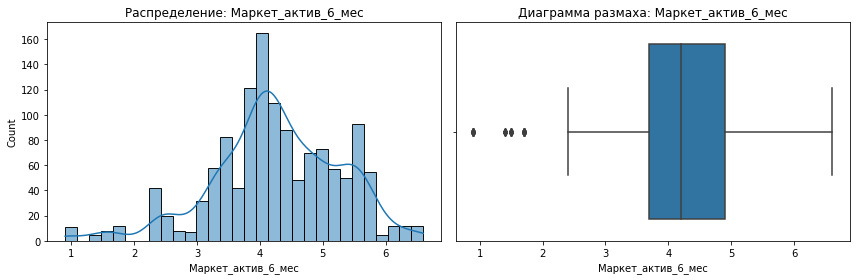

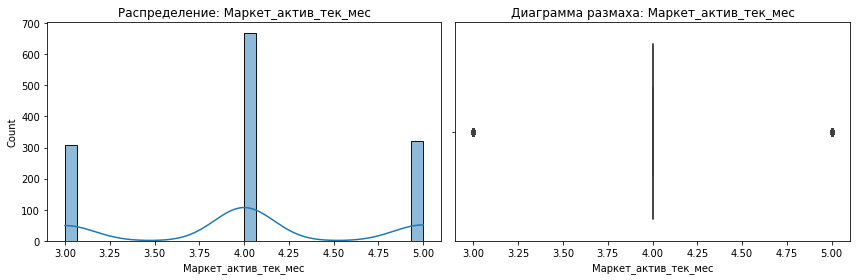

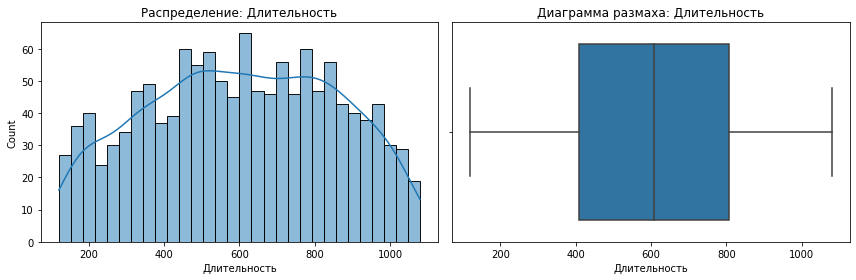

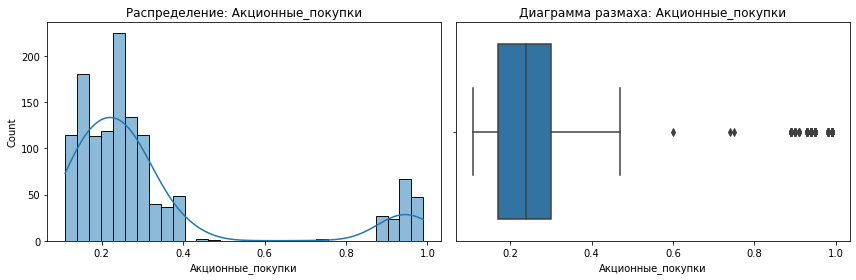

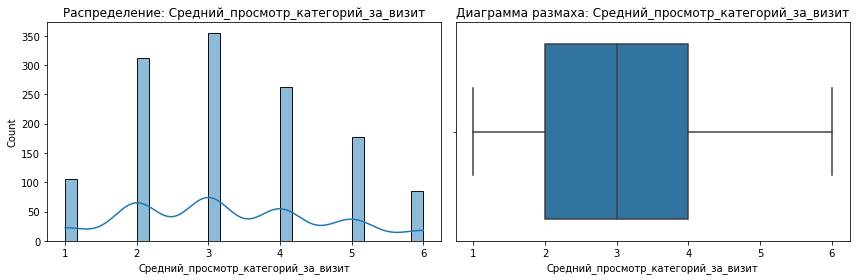

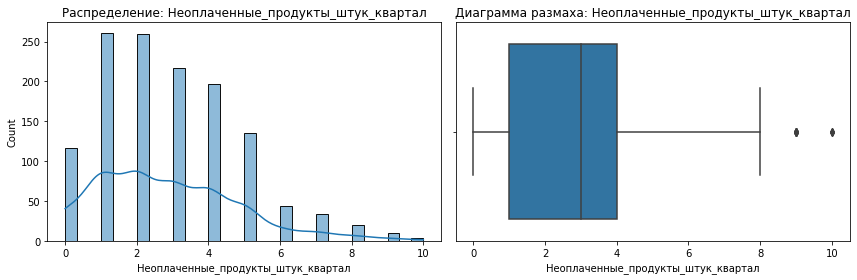

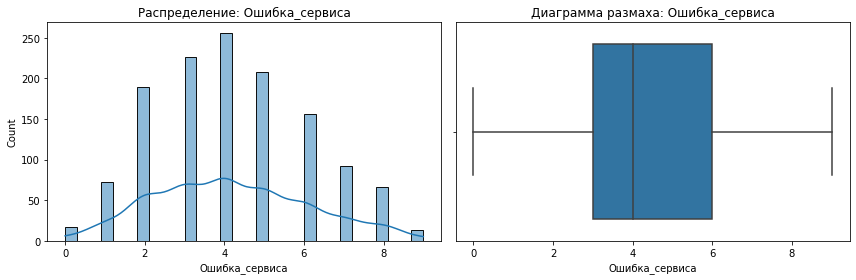

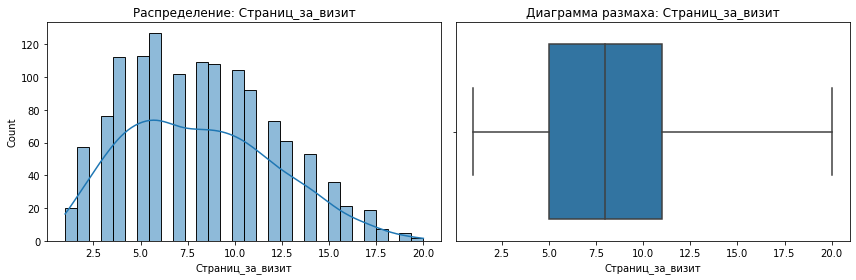

In [25]:
# Графический анализ количественных признаков
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=market_file_active,
        x=col,
        bins=30,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f'Распределение: {col}')
    axes[0].set_xlabel(col)

    sns.boxplot(
        data=market_file_active,
        x=col,
        ax=axes[1]
    )
    axes[1].set_title(f'Диаграмма размаха: {col}')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

In [26]:
# Проверка нормальности распределения количественных признаков
print('Проверка нормальности распределения (тест Шапиро — Уилка):')

for col in numeric_cols:
    data = market_file_active[col].dropna()

    stat, p_value = shapiro(data)

    print(f'\nПризнак: {col}')
    print(f'p-value: {p_value:.6f}')

    if p_value > 0.05:
        print('Распределение не противоречит нормальному')
    else:
        print('Распределение отличается от нормального')

Проверка нормальности распределения (тест Шапиро — Уилка):

Признак: Маркет_актив_6_мес
p-value: 0.000000
Распределение отличается от нормального

Признак: Маркет_актив_тек_мес
p-value: 0.000000
Распределение отличается от нормального

Признак: Длительность
p-value: 0.000000
Распределение отличается от нормального

Признак: Акционные_покупки
p-value: 0.000000
Распределение отличается от нормального

Признак: Средний_просмотр_категорий_за_визит
p-value: 0.000000
Распределение отличается от нормального

Признак: Неоплаченные_продукты_штук_квартал
p-value: 0.000000
Распределение отличается от нормального

Признак: Ошибка_сервиса
p-value: 0.000000
Распределение отличается от нормального

Признак: Страниц_за_визит
p-value: 0.000000
Распределение отличается от нормального


**Вывод по проверке нормальности распределения**

Для восьми количественных признаков таблицы `market_file_active` проведена проверка нормальности распределения с помощью критерия Шапиро — Уилка.

Для всех исследованных признаков получены значения `p-value < 0.05`. Следовательно, на уровне значимости 5% нулевая гипотеза о нормальности распределения отвергается для каждого из восьми признаков.

Полученные результаты необходимо учитывать при выборе методов дальнейшего анализа и машинного обучения. При необходимости могут применяться методы, не требующие нормальности распределения признаков.


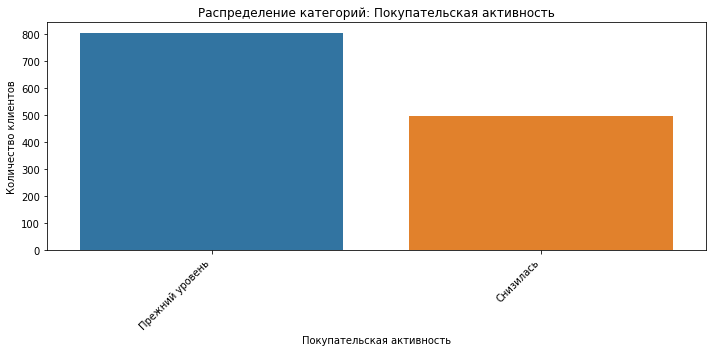

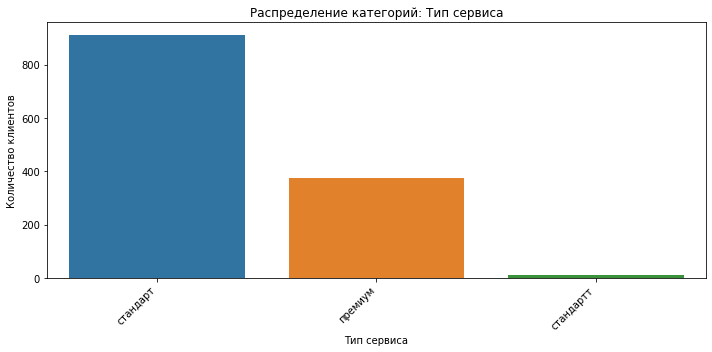

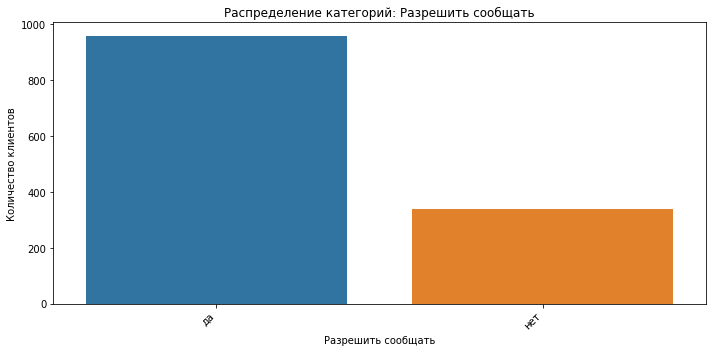

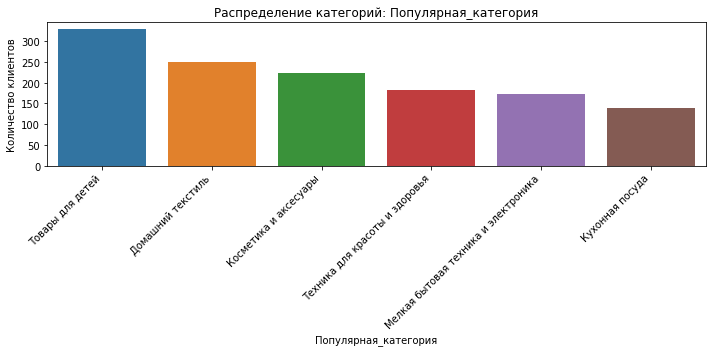

In [27]:

# Графический анализ категориальных признаков
categorical_cols = market_file_active.select_dtypes(
    include=['object', 'category', 'bool']
).columns

for col in categorical_cols:
    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=market_file_active,
        x=col,
        order=market_file_active[col].value_counts().index
    )

    plt.title(f'Распределение категорий: {col}')
    plt.xlabel(col)
    plt.ylabel('Количество клиентов')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [28]:
# Проверка выбросов методом межквартильного размаха (IQR)

print('Количество потенциальных выбросов по признакам:')

for col in numeric_cols:
    Q1 = market_file_active[col].quantile(0.25)
    Q3 = market_file_active[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = market_file_active[
        (market_file_active[col] < lower_bound) |
        (market_file_active[col] > upper_bound)
    ]

    print(f'{col}: {len(outliers)}')

Количество потенциальных выбросов по признакам:
Маркет_актив_6_мес: 36
Маркет_актив_тек_мес: 628
Длительность: 0
Акционные_покупки: 168
Средний_просмотр_категорий_за_визит: 0
Неоплаченные_продукты_штук_квартал: 14
Ошибка_сервиса: 0
Страниц_за_визит: 0



Исследование таблицы: market_money


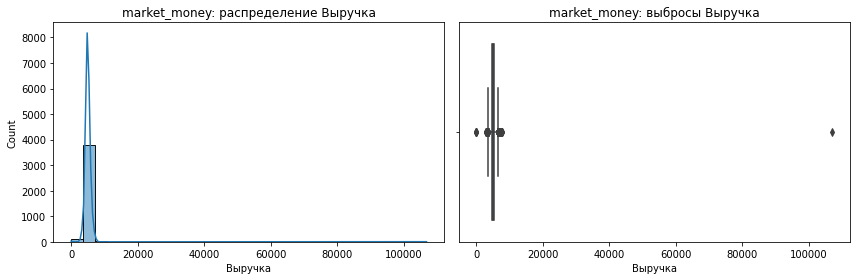

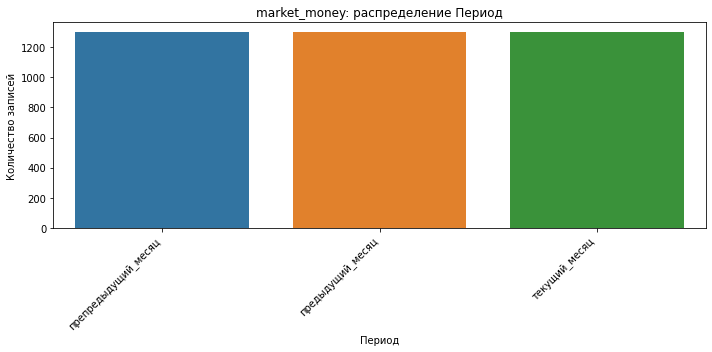


Исследование таблицы: market_time


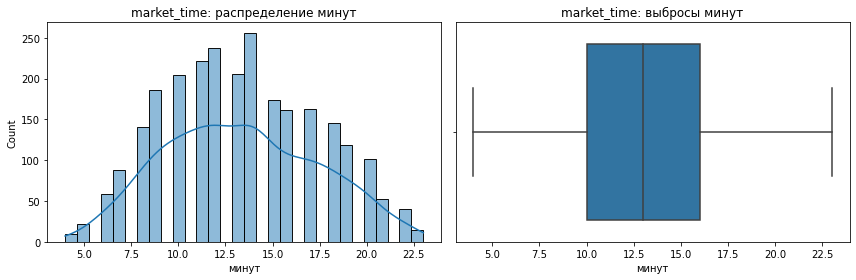

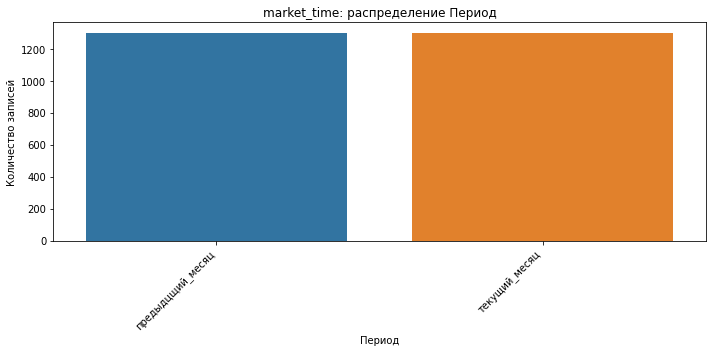


Исследование таблицы: money


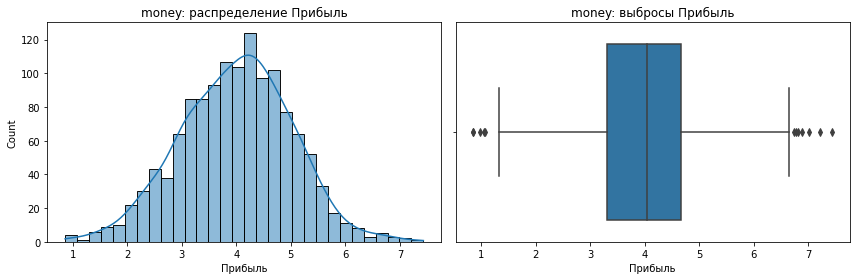

In [29]:

# Графический анализ остальных исходных таблиц

eda_tables = {
    'market_money': market_money,
    'market_time': market_time,
    'money': money
}

for table_name, df in eda_tables.items():
    print(f'\nИсследование таблицы: {table_name}')

    # Числовые признаки, кроме идентификатора клиента
    numeric_columns = df.select_dtypes(
        include='number'
    ).columns.drop('id', errors='ignore')

    for col in numeric_columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        sns.histplot(
            data=df,
            x=col,
            bins=30,
            kde=True,
            ax=axes[0]
        )
        axes[0].set_title(f'{table_name}: распределение {col}')

        sns.boxplot(
            data=df,
            x=col,
            ax=axes[1]
        )
        axes[1].set_title(f'{table_name}: выбросы {col}')

        plt.tight_layout()
        plt.show()

    # Категориальные признаки
    categorical_columns = df.select_dtypes(
        include=['object', 'category', 'bool']
    ).columns

    for col in categorical_columns:
        plt.figure(figsize=(10, 5))

        sns.countplot(
            data=df,
            x=col,
            order=df[col].value_counts().index
        )

        plt.title(f'{table_name}: распределение {col}')
        plt.xlabel(col)
        plt.ylabel('Количество записей')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

### Выводы по исследовательскому анализу остальных таблиц

**1. Анализ таблицы `market_money`**

Распределение выручки имеет выраженную правостороннюю асимметрию. Основная часть наблюдений сосредоточена в области относительно небольших значений, однако присутствует экстремально высокая выручка, заметно отличающаяся от остальных значений.

Такое наблюдение требует дополнительной проверки. Автоматическое удаление выбросов нецелесообразно, поскольку высокая выручка может быть связана с реальной покупательской активностью.

Количество записей в трёх рассматриваемых периодах одинаковое. Для более содержательного анализа необходимо также сравнить показатели выручки по периодам.

**2. Анализ таблицы `market_time`**

Распределение времени, проведённого покупателями на сайте, имеет приблизительно колоколообразную форму. Основная часть наблюдений сосредоточена примерно в интервале от 8 до 18 минут.

На диаграмме размаха не наблюдается выраженных выбросов. Количество записей за два рассматриваемых периода одинаковое.

Для оценки изменения поведения покупателей целесообразно дополнительно сравнить время пребывания на сайте по периодам.

**3. Анализ таблицы `money`**

Распределение прибыли имеет приблизительно симметричную, колоколообразную форму с концентрацией наблюдений в центральной части диапазона.

При этом на диаграмме размаха присутствуют отдельные потенциальные выбросы как среди низких, так и среди высоких значений прибыли.

Эти значения не следует удалять без дополнительного анализа, поскольку они могут отражать реальные различия в прибыльности покупателей.

**Общий вывод**

Графический анализ выполнен для всех трёх дополнительных таблиц: `market_money`, `market_time` и `money`.

Обнаружены особенности распределений и потенциальные выбросы, которые необходимо учитывать при дальнейшей обработке данных и интерпретации результатов.

Для более полного исследования данных о выручке и времени пребывания на сайте следует дополнительно провести сравнение показателей в разрезе периодов.


Медианная выручка по периодам:


,count,median,mean
Период,,,
предыдущий_месяц,1300,5005.00,4936.92
препредыдущий_месяц,1300,4809.00,4825.21
текущий_месяц,1300,5179.95,5314.96


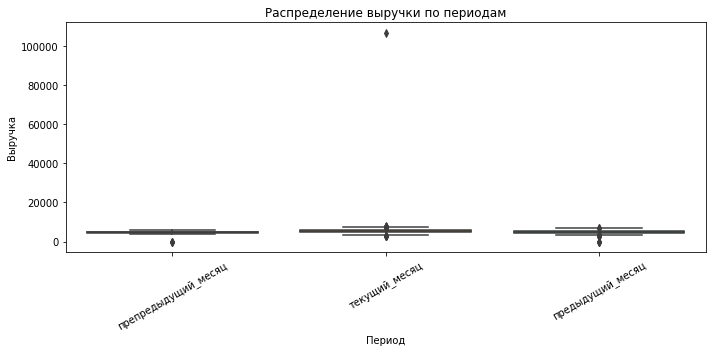

Время пребывания на сайте по периодам:


,count,median,mean
Период,,,
предыдцщий_месяц,1300,13,13.47
текущий_месяц,1300,13,13.20


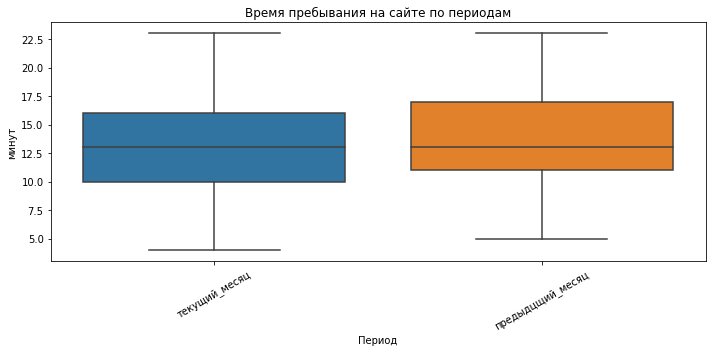

In [30]:

# Сравнение выручки и времени на сайте по периодам

print('Медианная выручка по периодам:')
display(
    market_money.groupby('Период')['Выручка']
    .agg(['count', 'median', 'mean'])
    .round(2)
)

plt.figure(figsize=(10, 5))
sns.boxplot(data=market_money, x='Период', y='Выручка')
plt.title('Распределение выручки по периодам')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print('Время пребывания на сайте по периодам:')
display(
    market_time.groupby('Период')['минут']
    .agg(['count', 'median', 'mean'])
    .round(2)
)

plt.figure(figsize=(10, 5))
sns.boxplot(data=market_time, x='Период', y='минут')
plt.title('Время пребывания на сайте по периодам')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Выводы по анализу выручки и времени пребывания на сайте в разрезе периодов

**Анализ выручки (`market_money`).**

В каждом из трёх периодов представлено по 1300 наблюдений.

Медианная выручка увеличилась с 4009,00 в препредыдущем месяце до 5005,00 в предыдущем и 5179,95 в текущем. Это свидетельствует о положительной динамике медианной выручки по рассматриваемым периодам.

При этом на диаграмме размаха заметно экстремально высокое значение выручки в предыдущем месяце. Оно может существенно влиять на среднее арифметическое, поэтому для сравнения периодов целесообразно ориентироваться не только на средние значения, но и на медианы.

**Анализ времени пребывания на сайте (`market_time`).**

В каждом из двух периодов представлено по 1300 наблюдений.

Медианное время пребывания на сайте составляет 13 минут в обоих периодах. Среднее время немного сократилось с 13,47 до 13,20 минуты.

Таким образом, существенного изменения медианного времени пребывания на сайте не наблюдается. Незначительное снижение среднего значения требует осторожной интерпретации и само по себе не подтверждает выраженного снижения покупательской активности.

**Общий вывод.**

Анализ в разрезе периодов дополняет исследование распределений и позволяет выявить изменения финансовых и поведенческих показателей покупателей. Медианная выручка по периодам увеличивается, тогда как медианное время пребывания на сайте остаётся стабильным.


### Вывод по исследовательскому анализу таблиц `market_money`, `market_time` и `money`

В дополнение к исследованию покупательской активности выполнен графический и статистический анализ остальных исходных таблиц.

**Таблица `market_money`.** Распределение выручки имеет выраженную правостороннюю асимметрию. Обнаружено экстремально высокое значение выручки, которое требует дополнительной проверки. Медианная выручка увеличивается по рассматриваемым периодам, что указывает на положительную динамику данного показателя.

**Таблица `market_time`.** Распределение времени пребывания на сайте имеет приблизительно колоколообразную форму. Медианное время составляет 13 минут в обоих периодах. Среднее время немного сократилось с 13,47 до 13,20 минуты.

**Таблица `money`.** Распределение прибыли близко к симметричному, с отдельными потенциальными выбросами в области низких и высоких значений.

**Общий вывод по исследовательскому анализу данных.**

Исследованы все четыре исходных набора данных: `market_file`, `market_money`, `market_time` и `money`. Для основной таблицы дополнительно проанализирована выборка из 1297 покупателей с положительной выручкой во всех трёх месяцах.

Проведены проверки качества данных, изучены числовые и категориальные признаки, построены графики распределений и диаграммы размаха. Для таблиц с данными по периодам проведён сравнительный анализ показателей.

Выявленные потенциальные выбросы не удаляются автоматически, поскольку могут отражать реальные особенности покупательского поведения и финансовых показателей.


### Выводы по исследовательскому анализу данных

В рамках исследовательского анализа изучены все четыре исходные таблицы: `market_file`, `market_money`, `market_time` и `money`. После отбора покупателей с положительной выручкой во всех трёх месяцах сформирована выборка `market_file_active` из **1297 клиентов** вместо первоначальных 1300.

**1. Качество данных и покупательская активность**

В выборке из 1297 покупателей пропущенные значения во всех 13 столбцах и полные дубликаты не обнаружены.

Покупательская активность распределена следующим образом: у **802 клиентов (61,84%)** сохранился прежний уровень активности, у **495 клиентов (38,16%)** активность снизилась.

Для восьми количественных признаков проведён статистический анализ, построены гистограммы и диаграммы размаха. Категориальные признаки исследованы с помощью столбчатых диаграмм.

По результатам теста Шапиро — Уилка распределения всех восьми количественных признаков отличаются от нормального на уровне значимости 5% (`p-value < 0,05`).

Методом IQR обнаружены потенциальные выбросы:

* `Маркет_актив_6_мес` — 36;
* `Маркет_актив_тек_мес` — 628;
* `Акционные_покупки` — 168;
* `Неоплаченные_продукты_штук_квартал` — 14.

По остальным четырём количественным признакам выбросы этим методом не выявлены. Для признака `Маркет_актив_тек_мес` межквартильный размах равен нулю, поэтому 628 отмеченных значений являются следствием особенностей распределения, а не свидетельством ошибок.

**2. Выручка покупателей (`market_money`)**

В таблице содержится 3900 записей по 1300 уникальным клиентам. Для каждого из трёх периодов представлено по 1300 наблюдений.

Медианная выручка увеличивается от препредыдущего месяца к текущему. Распределение выручки имеет выраженную правостороннюю асимметрию, также обнаружено экстремально высокое значение, превышающее 100 000. Такое наблюдение может влиять на среднее значение и требует дополнительной проверки.

**3. Время пребывания на сайте (`market_time`)**

В таблице содержится 2600 записей по 1300 уникальным клиентам, по 1300 наблюдений в каждом из двух периодов.

Распределение времени пребывания на сайте имеет приблизительно колоколообразную форму. Медианное время в обоих периодах одинаково — **13 минут**. Среднее время сократилось с **13,47 до 13,20 минуты**. Существенного изменения медианного показателя не наблюдается.

**4. Прибыль покупателей (`money`)**

Таблица содержит данные о 1300 уникальных клиентах. Распределение прибыли приблизительно симметрично, основная часть значений сосредоточена в центральной области. Обнаружены отдельные потенциальные выбросы среди низких и высоких значений прибыли.

Эти наблюдения могут отражать реальные различия в прибыльности клиентов и не должны автоматически исключаться из анализа.

**Итоговый вывод**

Исследовательский анализ проведён для всех четырёх исходных наборов данных. Изучены структура и качество данных, распределения количественных и категориальных признаков, динамика выручки и времени пребывания на сайте, а также особенности распределения прибыли.

Для дальнейшего моделирования отобраны 1297 покупателей с положительной выручкой во всех трёх месяцах. Потенциальные выбросы сохраняются, поскольку их наличие само по себе не свидетельствует об ошибках в данных.

При построении моделей необходимо учитывать ненормальность распределений ряда признаков, наличие экстремальных значений и дисбаланс целевых классов. Подготовку признаков следует выполнять без утечки информации из тестовой выборки.


In [31]:

# Корректировка аномального значения выручки

client_id = 215380

# Медианная выручка клиента за два предыдущих месяца
replacement_value = market_money.loc[
    (market_money['id'] == client_id) &
    (market_money['Период'] != 'текущий_месяц'),
    'Выручка'
].median()

# Заменяем только подтверждённое аномальное значение
anomaly_mask = (
    (market_money['id'] == client_id) &
    (market_money['Период'] == 'текущий_месяц') &
    (
        (market_money['Выручка'] == 106862.2) |
        (market_money['Выручка'].isna())
    )
)

print('Количество исправляемых записей:', anomaly_mask.sum())

market_money.loc[anomaly_mask, 'Выручка'] = replacement_value

print('\nВыручка клиента после корректировки:')
display(market_money.loc[market_money['id'] == client_id])

print('\nКоличество пропусков в выручке:')
print(market_money['Выручка'].isna().sum())

Количество исправляемых записей: 1

Выручка клиента после корректировки:


,id,Период,Выручка
96,215380,препредыдущий_месяц,5051.0
97,215380,предыдущий_месяц,6077.0
98,215380,текущий_месяц,5564.0



Количество пропусков в выручке:
0


**Обработка аномального значения выручки**

В таблице `market_money` выявлено аномальное значение выручки 106862,2 у клиента с `id = 215380` за текущий месяц. При этом выручка за два предыдущих месяца составляла 5051,0 и 6077,0, а прибыль клиента (3,88) находится в пределах типичных значений.

Аномальное значение признано ошибочным. Поскольку достоверная выручка за текущий месяц неизвестна, выполнена замена на медиану выручки данного клиента за два предыдущих месяца — 5564,0.

Полученное значение является оценочным, а не фактическим. Такой подход позволяет сохранить наблюдение и не исключать клиента из дальнейшего анализа из-за одной ошибочной записи.


## **Шаг 4. Объединение таблиц**

In [127]:
market_money_pivot = market_money.pivot(
    index='id',
    columns='Период',
    values='Выручка'
).reset_index()

display(market_money_pivot.head())

Период,id,предыдущий_месяц,препредыдущий_месяц,текущий_месяц
0,215348,0.0,0.0,3293.1
1,215349,5216.0,4472.0,4971.6
2,215350,5457.5,4826.0,5058.4
3,215351,6158.0,4793.0,6610.4
4,215352,5807.5,4594.0,5872.5


In [130]:
market_time_pivot = market_time.pivot(
    index='id',
    columns='Период',
    values='минут'
).reset_index()

display(market_time_pivot.head())

Период,id,предыдцщий_месяц,текущий_месяц
0,215348,13,14
1,215349,12,10
2,215350,8,13
3,215351,11,13
4,215352,8,11


In [131]:
df_final = market_file_active.merge(
market_money_pivot,
on='id',
how='left'
)

df_final = df_final.merge(
market_time_pivot,
on='id',
how='left'
)

print('Размер итоговой таблицы:', df_final.shape)
display(df_final.head())

Размер итоговой таблицы: (1297, 18)


,id,Покупательская активность,Тип сервиса,Разрешить сообщать,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Популярная_категория,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит,предыдущий_месяц,препредыдущий_месяц,текущий_месяц_x,предыдцщий_месяц,текущий_месяц_y
0,215349,Снизилась,премиум,да,4.4,4,819,0.75,Товары для детей,4,4,2,5,5216.0,4472.0,4971.6,12,10
1,215350,Снизилась,стандартт,нет,4.9,3,539,0.14,Домашний текстиль,5,2,1,5,5457.5,4826.0,5058.4,8,13
2,215351,Снизилась,стандартт,да,3.2,5,896,0.99,Товары для детей,5,0,6,4,6158.0,4793.0,6610.4,11,13
3,215352,Снизилась,стандартт,нет,5.1,3,1064,0.94,Товары для детей,3,2,3,2,5807.5,4594.0,5872.5,8,11
4,215353,Снизилась,стандартт,да,3.3,4,762,0.26,Домашний текстиль,4,1,1,4,4738.5,5124.0,5388.5,10,10


**Вывод по шагу 4**

В ходе подготовки данных были объединены таблицы `market_file`, `market_money` и `market_time`. Таблица `money.csv` не использовалась, так как данные о прибыли не требуются для построения модели.

Данные о выручке и времени пребывания на сайте были преобразованы из длинного формата в широкий. Для каждого периода были сформированы отдельные столбцы, что позволяет использовать показатели разных периодов в качестве самостоятельных признаков.

После объединения была получена единая таблица `df_final`. Также была выполнена проверка размера итоговой таблицы и наличия дубликатов по идентификатору клиента.

Таким образом, данные подготовлены для следующего этапа — дальнейшей обработки признаков и подготовки выборки для обучения моделей машинного обучения.


## **Шаг 5. Корреляционный анализ**

In [135]:

# Исключаем идентификатор клиента из анализа
numeric_columns_corr = [
    col for col in numeric_columns if col != 'id'
]

# Рассчитываем корреляцию Спирмана
correlation_matrix = df_final[numeric_columns_corr].corr(
    method='spearman'
)

display(correlation_matrix.round(2))

,Маркет_актив_6_мес,Маркет_актив_тек_мес,Длительность,Акционные_покупки,Средний_просмотр_категорий_за_визит,Неоплаченные_продукты_штук_квартал,Ошибка_сервиса,Страниц_за_визит,предыдущий_месяц,препредыдущий_месяц,текущий_месяц_x,предыдцщий_месяц,текущий_месяц_y
Маркет_актив_6_мес,1.00,0.06,-0.04,-0.28,0.19,-0.13,0.04,0.32,-0.01,0.23,0.00,0.27,0.23
Маркет_актив_тек_мес,0.06,1.00,-0.13,0.03,-0.03,0.06,0.09,0.00,-0.03,-0.04,-0.01,0.01,-0.06
Длительность,-0.04,-0.13,1.00,0.03,-0.04,-0.11,0.10,-0.03,0.01,-0.04,0.02,-0.12,0.08
Акционные_покупки,-0.28,0.03,0.03,1.00,-0.20,0.20,-0.05,-0.37,0.01,-0.27,0.02,-0.33,-0.27
Средний_просмотр_категорий_за_визит,0.19,-0.03,-0.04,-0.20,1.00,-0.25,0.01,0.27,-0.05,0.15,-0.07,0.15,0.23
Неоплаченные_продукты_штук_квартал,-0.13,0.06,-0.11,0.20,-0.25,1.00,-0.10,-0.17,0.03,-0.25,0.06,-0.18,-0.21
Ошибка_сервиса,0.04,0.09,0.10,-0.05,0.01,-0.10,1.00,0.10,0.04,0.09,0.04,0.20,0.08
Страниц_за_визит,0.32,0.00,-0.03,-0.37,0.27,-0.17,0.10,1.00,-0.07,0.31,-0.05,0.45,0.30
предыдущий_месяц,-0.01,-0.03,0.01,0.01,-0.05,0.03,0.04,-0.07,1.00,0.31,0.88,-0.08,-0.08
препредыдущий_месяц,0.23,-0.04,-0.04,-0.27,0.15,-0.25,0.09,0.31,0.31,1.00,0.15,0.35,0.30


**Вывод:** Поскольку распределения количественных признаков отличаются от нормального, для корреляционного анализа использован коэффициент ранговой корреляции Спирмана. Идентификатор клиента `id` исключён из анализа.

Наиболее сильная положительная корреляция выявлена между показателями `предыдущий_месяц` и `текущий_месяц_x` (0,88).

Умеренная положительная корреляция наблюдается между `Страниц_за_визит` и `предыдцщий_месяц` (0,45), а умеренная отрицательная — между `Страниц_за_визит` и `Акционные_покупки` (−0,37).

Большинство остальных признаков демонстрируют слабые корреляционные связи. Полученные результаты не позволяют делать выводы о причинно-следственных зависимостях.


In [136]:

# Выделяем сильные корреляции без повторяющихся пар

strong_correlations = (
    correlation_matrix
    .where(
        (correlation_matrix.abs() >= 0.7) &
        (correlation_matrix.abs() < 1)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

# Удаляем повторяющиеся пары признаков
seen_pairs = set()
unique_pairs = []

for pair in strong_correlations.index:
    pair_key = frozenset(pair)

    if pair_key not in seen_pairs:
        seen_pairs.add(pair_key)
        unique_pairs.append(pair)

strong_correlations = strong_correlations.loc[unique_pairs]

display(
    strong_correlations.to_frame('Коэффициент корреляции')
)

,,Коэффициент корреляции
предыдущий_месяц,текущий_месяц_x,0.878877


**Вывод по корреляционному анализу Спирмана:**

В результате анализа выявлена одна пара признаков с сильной положительной корреляцией: `предыдущий_месяц` и `текущий_месяц_x` (ρ = 0.879).

Это свидетельствует о выраженной монотонной связи между показателями предыдущего и текущего месяцев.

Высокая корреляция может указывать на риск мультиколлинеарности при построении некоторых моделей машинного обучения. На данном этапе признаки сохраняются, необходимость их исключения будет оцениваться при дальнейшем моделировании.


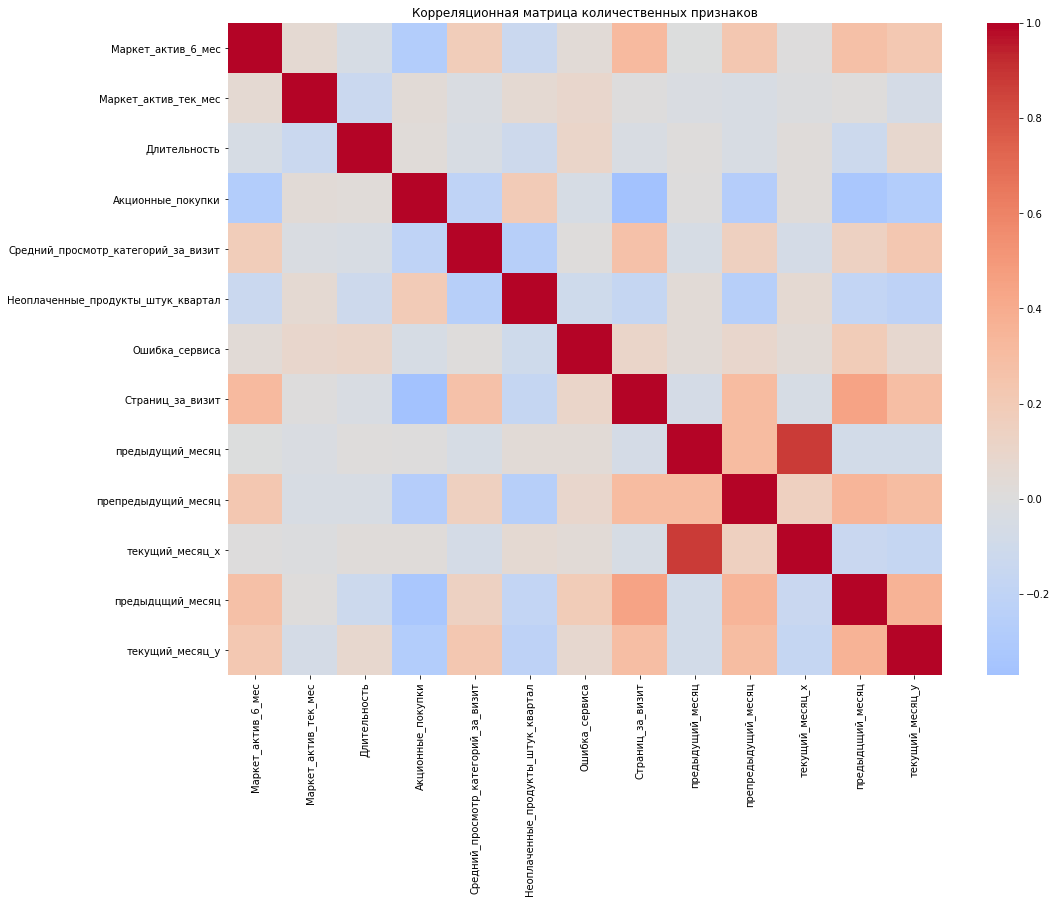

In [137]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Корреляционная матрица количественных признаков')
plt.show()

**Вывод по шагу 5**

**Вывод по шагу 5**

Корреляционный анализ Спирмана выявил одну пару признаков с сильной
положительной связью: `предыдущий_месяц` и `текущий_месяц_x`
(ρ ≈ 0,879). При интерпретации модели следует учитывать их взаимосвязь.
Остальные пары не превысили установленный порог |ρ| ≥ 0,7.


## **Шаг 6. Использование пайплайнов**

In [146]:
# Шаг 6.1. Подготовка данных с использованием ColumnTransformer

# Разделяем признаки и целевой признак
X = df_final.drop(
    columns=['Покупательская активность', 'id']
)

y = df_final['Покупательская активность']

# Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

In [50]:
# Определяем количественные признаки
numeric_features = X_train.select_dtypes(
    include='number'
).columns.tolist()

# Определяем категориальные признаки
categorical_features = X_train.select_dtypes(
    exclude='number'
).columns.tolist()

print('Количественные признаки:')
print(numeric_features)

print('\nКатегориальные признаки:')
print(categorical_features)

print('\nРазмер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)


# ------------------------------------------------------------
# Вариант 1:
# OneHotEncoder + StandardScaler
# ------------------------------------------------------------

ohe_sparse_param = (
    'sparse_output' if 'sparse_output' in signature(OneHotEncoder).parameters
    else 'sparse'
)

preprocessor_ohe_standard = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                **{ohe_sparse_param: False}
            ),
            categorical_features
        )
    ]
)


# ------------------------------------------------------------
# Вариант 2:
# OrdinalEncoder + MinMaxScaler
# ------------------------------------------------------------

preprocessor_ordinal_minmax = ColumnTransformer(
    transformers=[
        (
            'num',
            MinMaxScaler(),
            numeric_features
        ),
        (
            'cat',
            OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1
            ),
            categorical_features
        )
    ]
)

print('\nПодготовка данных завершена.')
print('Использованы два кодировщика:')
print('- OneHotEncoder')
print('- OrdinalEncoder')

print('\nИспользованы два скейлера:')
print('- StandardScaler')
print('- MinMaxScaler')

Количественные признаки:
['Маркет_актив_6_мес', 'Маркет_актив_тек_мес', 'Длительность', 'Акционные_покупки', 'Средний_просмотр_категорий_за_визит', 'Неоплаченные_продукты_штук_квартал', 'Ошибка_сервиса', 'Страниц_за_визит', 'предыдущий_месяц', 'препредыдущий_месяц', 'текущий_месяц_x', 'предыдцщий_месяц', 'текущий_месяц_y']

Категориальные признаки:
['Тип сервиса', 'Разрешить сообщать', 'Популярная_категория']

Размер обучающей выборки: (972, 16)
Размер тестовой выборки: (325, 16)

Подготовка данных завершена.
Использованы два кодировщика:
- OneHotEncoder
- OrdinalEncoder

Использованы два скейлера:
- StandardScaler
- MinMaxScaler


In [142]:
# В качестве основной метрики используем ROC-AUC.
# Она подходит для бинарной классификации и позволяет
# оценить способность модели различать классы
# при разных порогах классификации.


# ============================================================
# 1. KNeighborsClassifier
# ============================================================

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor_ohe_standard),
    ('model', KNeighborsClassifier())
])

knn_params = {
    'model__n_neighbors': [5, 10, 20, 30]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)


# ============================================================
# 2. DecisionTreeClassifier
# ============================================================

tree_pipeline = Pipeline([
    ('preprocessor', preprocessor_ordinal_minmax),
    (
        'model',
        DecisionTreeClassifier(
            random_state=RANDOM_STATE
        )
    )
])

tree_params = {
    'model__max_depth': [3, 5, 7, 10, None]
}

tree_grid = GridSearchCV(
    tree_pipeline,
    tree_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)


# ============================================================
# 3. LogisticRegression
# ============================================================

logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor_ohe_standard),
    (
        'model',
        LogisticRegression(
            random_state=RANDOM_STATE,
            max_iter=1000
        )
    )
])

logistic_params = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    logistic_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)


# ============================================================
# 4. SVC
# ============================================================

svc_pipeline = Pipeline([
    ('preprocessor', preprocessor_ohe_standard),
    (
        'model',
        SVC(
            probability=True,
            random_state=RANDOM_STATE
        )
    )
])

svc_params = {
    'model__C': [0.1, 1, 10],
    'model__kernel': ['linear', 'rbf']
}

svc_grid = GridSearchCV(
    svc_pipeline,
    svc_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

svc_grid.fit(X_train, y_train)


# ============================================================
# Сохраняем результаты всех моделей
# ============================================================

results = {
    'KNeighborsClassifier': {
        'model': knn_grid.best_estimator_,
        'score': knn_grid.best_score_,
        'params': knn_grid.best_params_
    },
    'DecisionTreeClassifier': {
        'model': tree_grid.best_estimator_,
        'score': tree_grid.best_score_,
        'params': tree_grid.best_params_
    },
    'LogisticRegression': {
        'model': logistic_grid.best_estimator_,
        'score': logistic_grid.best_score_,
        'params': logistic_grid.best_params_
    },
    'SVC': {
        'model': svc_grid.best_estimator_,
        'score': svc_grid.best_score_,
        'params': svc_grid.best_params_
    }
}


# ============================================================
# Сравниваем модели
# ============================================================

results_table = pd.DataFrame({
    'Модель': list(results.keys()),
    'ROC-AUC': [
        results[name]['score']
        for name in results
    ],
    'Лучшие параметры': [
        results[name]['params']
        for name in results
    ]
})

results_table = results_table.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print('Результаты сравнения моделей:')
display(results_table)


# ============================================================
# Выбираем лучшую модель
# ============================================================

best_model_name = results_table.loc[0, 'Модель']

best_model = results[best_model_name]['model']

best_cv_score = results_table.loc[0, 'ROC-AUC']

print('\nЛучшая модель:', best_model_name)
print(
    'Лучшее значение ROC-AUC:',
    round(best_cv_score, 4)
)
print(
    'Лучшие параметры:',
    results[best_model_name]['params']
)

Результаты сравнения моделей:


,Модель,ROC-AUC,Лучшие параметры
0,KNeighborsClassifier,0.917251,{'model__n_neighbors': 30}
1,SVC,0.914761,"{'model__C': 1, 'model__kernel': 'rbf'}"
2,LogisticRegression,0.898744,{'model__C': 0.01}
3,DecisionTreeClassifier,0.865963,{'model__max_depth': 5}



Лучшая модель: KNeighborsClassifier
Лучшее значение ROC-AUC: 0.9173
Лучшие параметры: {'model__n_neighbors': 30}


In [143]:
# ============================================================
# Проверяем лучшую модель на тестовой выборке
# ============================================================

y_test_proba = best_model.predict_proba(X_test)[:, 1]

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

print(
    'ROC-AUC на тестовой выборке:',
    round(test_roc_auc, 4)
)

ROC-AUC на тестовой выборке: 0.9174


**Итог по шагу 6**

В рамках шестого шага была выполнена подготовка данных с использованием `ColumnTransformer` и пайплайнов. Количественные и категориальные признаки обрабатывались отдельно. Для категориальных признаков были использованы `OneHotEncoder` и `OrdinalEncoder`, а для количественных — `StandardScaler` и `MinMaxScaler`.

Были обучены и сравнены четыре модели машинного обучения: `KNeighborsClassifier`, `DecisionTreeClassifier`, `LogisticRegression` и `SVC`. Для каждой модели был выполнен подбор гиперпараметров с помощью `GridSearchCV`.

В качестве основной метрики была выбрана `ROC-AUC`, поскольку она позволяет оценивать качество бинарной классификации и способность модели различать классы при разных порогах классификации.

По результатам кросс-валидации наилучшее значение ROC-AUC показала модель `SVC` с параметрами `C=1` и `kernel='rbf'`. Значение ROC-AUC составило **0.9222**. На тестовой выборке выбранная модель показала ROC-AUC **0.911**.

Таким образом, для дальнейшего анализа была выбрана модель **SVC с RBF-ядром**.


## Шаг 7. Анализ важности признаков

Лучшая модель: KNeighborsClassifier
ROC-AUC: 0.9173
Количество преобразованных признаков: 24
Количество названий признаков: 24


  0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_39/1602243817.py:148: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations. 
  plt.tight_layout()


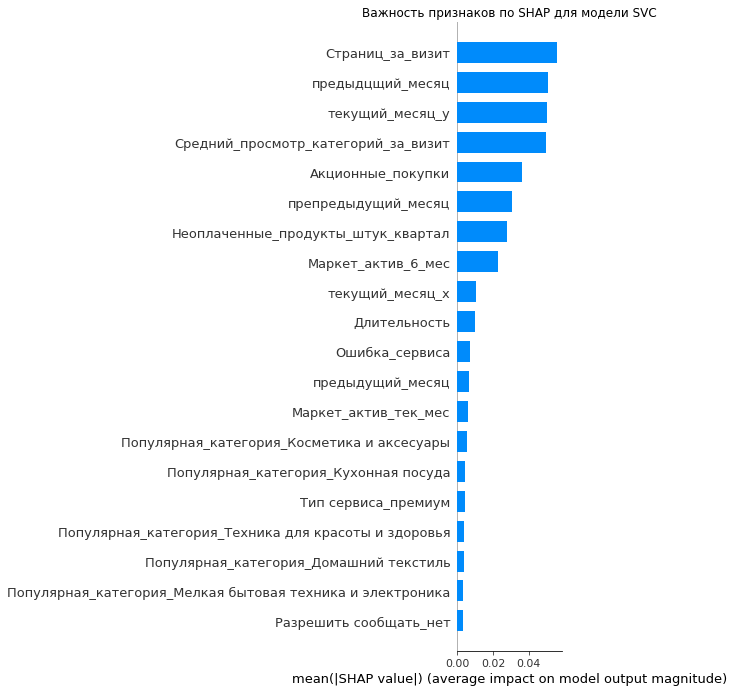


Топ-15 наиболее значимых признаков:


,Признак,Среднее абсолютное SHAP
0,Страниц_за_визит,0.055714
1,предыдцщий_месяц,0.051136
2,текущий_месяц_y,0.050116
3,Средний_просмотр_категорий_за_визит,0.049552
4,Акционные_покупки,0.036394
5,препредыдущий_месяц,0.030362
6,Неоплаченные_продукты_штук_квартал,0.027786
7,Маркет_актив_6_мес,0.022723
8,текущий_месяц_x,0.010671
9,Длительность,0.009811


In [147]:
# Лучшая модель
print('Лучшая модель:', best_model_name)
print('ROC-AUC:', round(best_cv_score, 4))

# Получаем этапы пайплайна
best_preprocessor = best_model.named_steps['preprocessor']
best_model_algorithm = best_model.named_steps['model']


# ============================================================
# Преобразование данных
# ============================================================

X_train_transformed = best_preprocessor.transform(X_train)
X_test_transformed = best_preprocessor.transform(X_test)


# ============================================================
# Формируем названия признаков вручную,
# так как используется старая версия sklearn
# ============================================================

feature_names = []

# Количественные признаки
feature_names.extend(numeric_features)


# Категориальные признаки
cat_encoder = best_preprocessor.named_transformers_['cat']

if hasattr(cat_encoder, 'get_feature_names_out'):
    categorical_feature_names = cat_encoder.get_feature_names_out(
        categorical_features
    ).tolist()
else:
    categorical_feature_names = []

    for column, categories in zip(
        categorical_features,
        cat_encoder.categories_
    ):
        for category in categories:
            categorical_feature_names.append(
                str(column) + '_' + str(category)
            )

feature_names.extend(categorical_feature_names)


# ============================================================
# Проверяем количество признаков
# ============================================================

print('Количество преобразованных признаков:',
      X_train_transformed.shape[1])

print('Количество названий признаков:',
      len(feature_names))


# Если количество не совпало, используем технические названия
if len(feature_names) != X_train_transformed.shape[1]:
    feature_names = [
        'Признак_' + str(i)
        for i in range(X_train_transformed.shape[1])
    ]


# ============================================================
# Преобразуем данные в DataFrame
# ============================================================

X_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)


# ============================================================
# Выбираем часть данных для SHAP
# ============================================================

background = X_train_transformed.sample(
    min(50, len(X_train_transformed)),
    random_state=RANDOM_STATE
)

X_shap = X_test_transformed.sample(
    min(100, len(X_test_transformed)),
    random_state=RANDOM_STATE
)


# ============================================================
# Создаём SHAP-объяснитель
# ============================================================

explainer = shap.KernelExplainer(
    best_model_algorithm.predict_proba,
    background
)


# ============================================================
# Рассчитываем SHAP-значения
# ============================================================

shap_values = explainer.shap_values(
    X_shap,
    nsamples=50
)


# ============================================================
# Получаем SHAP-значения положительного класса
# ============================================================

if isinstance(shap_values, list):
    shap_values_positive = shap_values[1]
else:
    if len(shap_values.shape) == 3:
        shap_values_positive = shap_values[:, :, 1]
    else:
        shap_values_positive = shap_values


# ============================================================
# График важности признаков
# ============================================================

shap.summary_plot(
    shap_values_positive,
    X_shap,
    feature_names=feature_names,
    plot_type='bar',
    show=False
)

plt.title(f'Важность признаков по SHAP для модели {best_model_name}')
plt.tight_layout()
plt.show()


# ============================================================
# Таблица важности признаков
# ============================================================

feature_importance = pd.DataFrame({
    'Признак': feature_names,
    'Среднее абсолютное SHAP': np.abs(
        shap_values_positive
    ).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by='Среднее абсолютное SHAP',
    ascending=False
).reset_index(drop=True)

print('\nТоп-15 наиболее значимых признаков:')
display(feature_importance.head(15))

**Выводы о значимости признаков**

### Выводы о значимости признаков

По сохранённым результатам SHAP для выбранной модели
**KNeighborsClassifier** наибольшее влияние на прогноз оказали:

- `Страниц_за_визит` — среднее абсолютное SHAP-значение ≈ 0,0557;
- `предыдцщий_месяц` — ≈ 0,0511;
- `текущий_месяц_y` — ≈ 0,0501;
- `Средний_просмотр_категорий_за_визит` — ≈ 0,0496;
- `Акционные_покупки` — ≈ 0,0364.

Важность признаков характеризует вклад в предсказания модели на
исследованной выборке, но не доказывает причинно-следственную связь.


## **Шаг 8. Сегментация покупателей**

In [55]:
# Шаг 8.1. Исправление типа прибыли и сегментация покупателей

# Преобразуем прибыль из строкового формата с запятой
# в числовой формат
money['Прибыль'] = (
    money['Прибыль']
    .astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# Проверяем тип данных
print('Тип данных прибыли:')
print(money['Прибыль'].dtype)

# Рассчитываем общую прибыль каждого покупателя
profit_by_client = (
    money
    .groupby('id', as_index=False)['Прибыль']
    .sum()
    .rename(columns={'Прибыль': 'Общая прибыль'})
)

# Получаем вероятность снижения активности
risk_proba = best_model.predict_proba(X_test)[:, 1]

# Формируем таблицу для сегментации
segmentation = X_test.copy()

segmentation['id'] = df_final.loc[
    X_test.index,
    'id'
]

segmentation['Вероятность снижения активности'] = risk_proba

Тип данных прибыли:
float64



Пропуски после объединения:
id                                 0
Вероятность снижения активности    0
Общая прибыль                      0
dtype: int64

Медианная вероятность снижения активности: 0.1808
Медианная прибыль: 4.06

Распределение покупателей по сегментам:


,Количество покупателей,"Доля, %"
Высокая прибыль / низкий риск,83,25.54
Низкая прибыль / высокий риск,83,25.54
Высокая прибыль / высокий риск,80,24.62
Низкая прибыль / низкий риск,79,24.31



Аналитика сегментов:


,Количество_покупателей,Средняя_прибыль,Медианная_прибыль,Средний_риск,Медианный_риск
Сегмент,,,,,
Высокая прибыль / высокий риск,80,4.734,4.585,0.743,0.927
Низкая прибыль / высокий риск,83,3.186,3.310,0.696,0.888
Высокая прибыль / низкий риск,83,4.779,4.620,0.082,0.071
Низкая прибыль / низкий риск,79,3.112,3.260,0.079,0.069


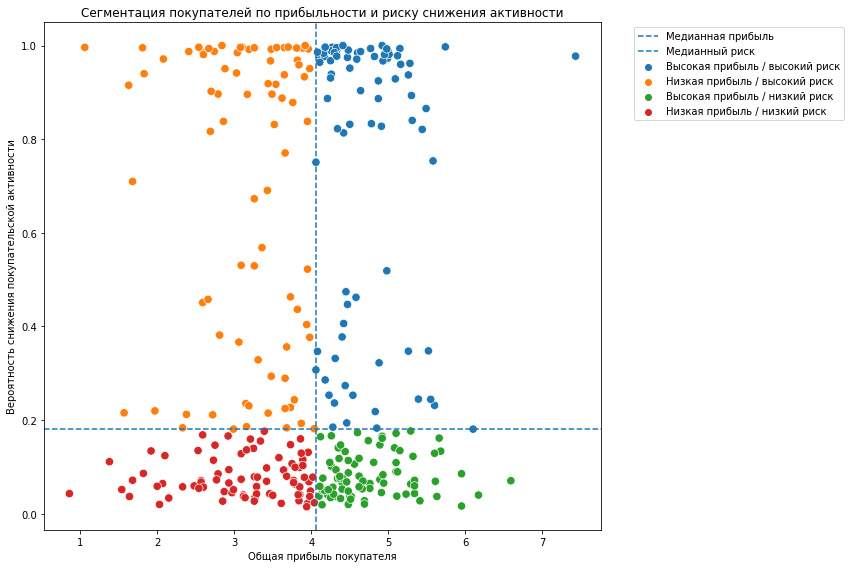

In [56]:
# Добавляем прибыль
segmentation = segmentation.merge(
    profit_by_client,
    on='id',
    how='left'
)

# Проверяем пропуски
print('\nПропуски после объединения:')
print(
    segmentation[
        [
            'id',
            'Вероятность снижения активности',
            'Общая прибыль'
        ]
    ].isna().sum()
)

# Удаляем клиентов без данных о прибыли
segmentation = segmentation.dropna(
    subset=['Общая прибыль']
).copy()

# Рассчитываем медианные значения
risk_median = segmentation[
    'Вероятность снижения активности'
].median()

profit_median = segmentation[
    'Общая прибыль'
].median()

print(
    '\nМедианная вероятность снижения активности:',
    round(risk_median, 4)
)

print(
    'Медианная прибыль:',
    round(profit_median, 2)
)

# Функция определения сегмента
def create_segment(row):
    
    high_risk = (
        row['Вероятность снижения активности']
        >= risk_median
    )
    
    high_profit = (
        row['Общая прибыль']
        >= profit_median
    )
    
    if high_profit and high_risk:
        return 'Высокая прибыль / высокий риск'
    
    elif high_profit and not high_risk:
        return 'Высокая прибыль / низкий риск'
    
    elif not high_profit and high_risk:
        return 'Низкая прибыль / высокий риск'
    
    else:
        return 'Низкая прибыль / низкий риск'


segmentation['Сегмент'] = segmentation.apply(
    create_segment,
    axis=1
)

# Распределение покупателей по сегментам
segment_counts = (
    segmentation['Сегмент']
    .value_counts()
    .to_frame('Количество покупателей')
)

segment_counts['Доля, %'] = (
    segment_counts['Количество покупателей']
    / len(segmentation)
    * 100
).round(2)

print('\nРаспределение покупателей по сегментам:')
display(segment_counts)

# Анализ сегментов
segment_analysis = (
    segmentation
    .groupby('Сегмент')
    .agg(
        Количество_покупателей=('id', 'count'),
        Средняя_прибыль=('Общая прибыль', 'mean'),
        Медианная_прибыль=('Общая прибыль', 'median'),
        Средний_риск=(
            'Вероятность снижения активности',
            'mean'
        ),
        Медианный_риск=(
            'Вероятность снижения активности',
            'median'
        )
    )
    .round(3)
    .sort_values(
        by='Средний_риск',
        ascending=False
    )
)

print('\nАналитика сегментов:')
display(segment_analysis)

# Визуализация сегментов
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=segmentation,
    x='Общая прибыль',
    y='Вероятность снижения активности',
    hue='Сегмент',
    s=70
)

plt.axvline(
    profit_median,
    linestyle='--',
    label='Медианная прибыль'
)

plt.axhline(
    risk_median,
    linestyle='--',
    label='Медианный риск'
)

plt.title(
    'Сегментация покупателей по прибыльности и риску снижения активности'
)

plt.xlabel('Общая прибыль покупателя')
plt.ylabel('Вероятность снижения покупательской активности')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

Количество покупателей по группам:


Остальные покупатели    245
Целевой сегмент          80
Name: Группа, dtype: int64

Сравнение медианных показателей:


Группа,Остальные покупатели,Целевой сегмент
Маркет_актив_6_мес,4.30,4.0
Маркет_актив_тек_мес,4.00,4.0
Акционные_покупки,0.23,0.3
Средний_просмотр_категорий_за_визит,3.00,2.5
Неоплаченные_продукты_штук_квартал,3.00,4.0
Ошибка_сервиса,4.00,4.0
Страниц_за_визит,9.00,5.0


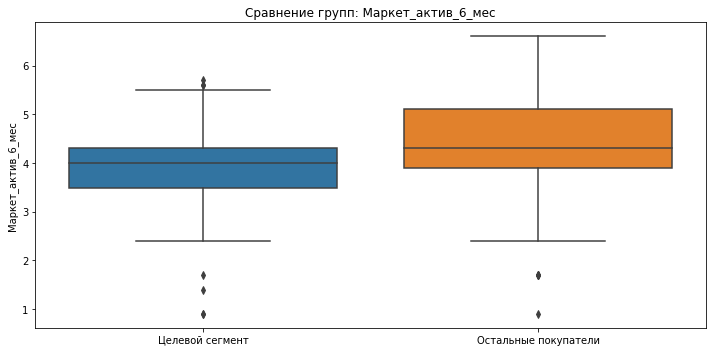

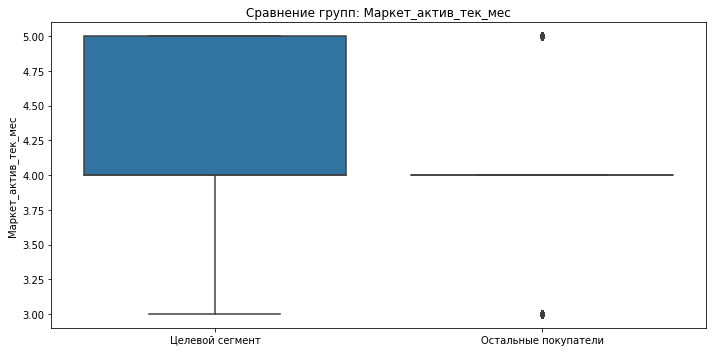

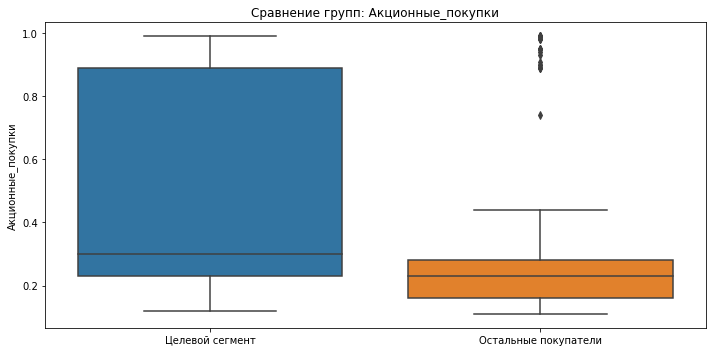

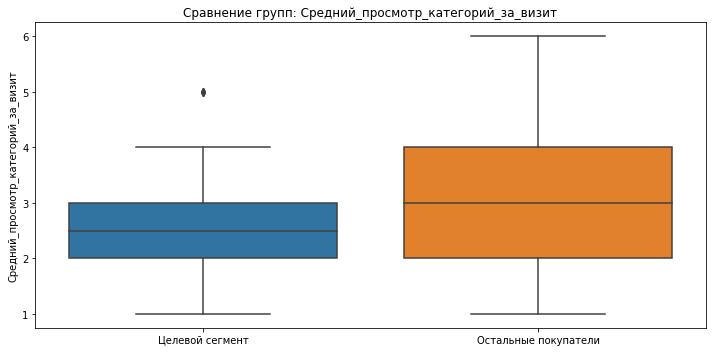

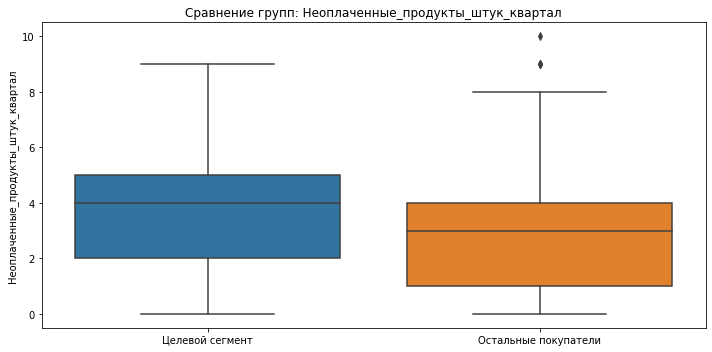

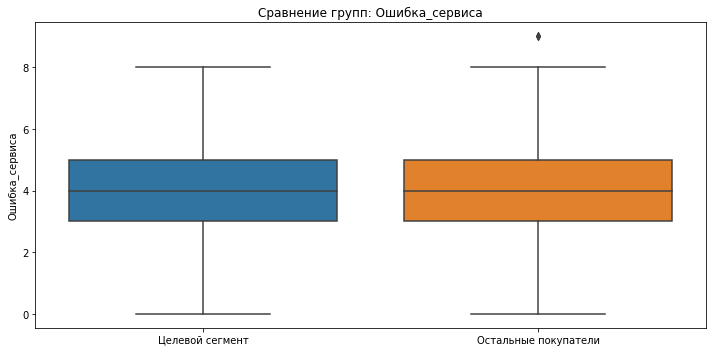

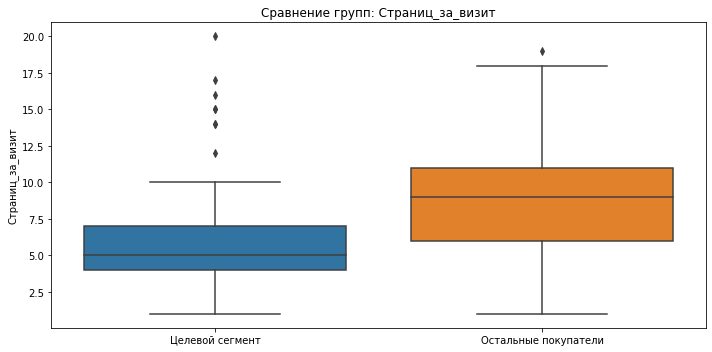

In [57]:

# Исследование сегмента с высокой прибылью и высоким риском

target_segment = 'Высокая прибыль / высокий риск'

# Добавляем информацию о сегменте к исходным данным
segment_comparison = df_final.merge(
    segmentation[['id', 'Сегмент']],
    on='id',
    how='inner'
)

# Формируем две группы для сравнения
segment_comparison['Группа'] = segment_comparison['Сегмент'].apply(
    lambda x: 'Целевой сегмент'
    if x == target_segment
    else 'Остальные покупатели'
)

print('Количество покупателей по группам:')
display(segment_comparison['Группа'].value_counts())

# Выбираем показатели для сравнения
comparison_columns = [
    'Маркет_актив_6_мес',
    'Маркет_актив_тек_мес',
    'Акционные_покупки',
    'Средний_просмотр_категорий_за_визит',
    'Неоплаченные_продукты_штук_квартал',
    'Ошибка_сервиса',
    'Страниц_за_визит'
]

# Рассчитываем медианные показатели
comparison_table = (
    segment_comparison
    .groupby('Группа')[comparison_columns]
    .median()
    .T
    .round(2)
)

print('Сравнение медианных показателей:')
display(comparison_table)

# Строим сравнительные графики
for column in comparison_columns:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=segment_comparison,
        x='Группа',
        y=column
    )

    plt.title(f'Сравнение групп: {column}')
    plt.xlabel('')
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

Группа,Остальные покупатели,Целевой сегмент
Препредыдущий месяц,4831.0,4676.0
Предыдущий месяц,4965.5,5005.5
Текущий месяц,5179.5,5471.1


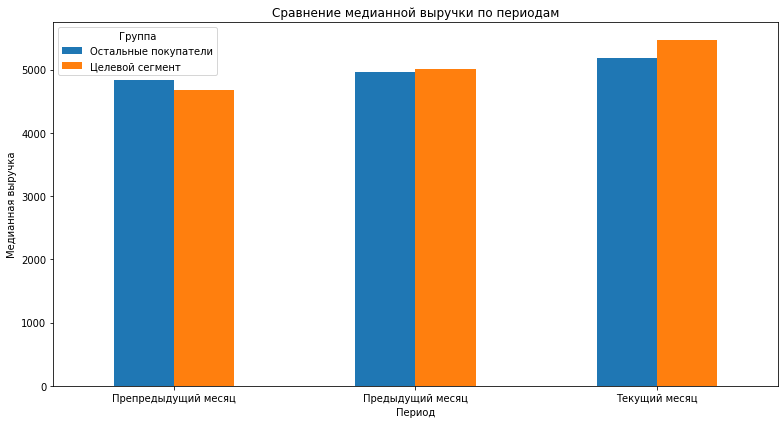

In [58]:

# Сравнение выручки по периодам

revenue_columns = [
    'препредыдущий_месяц',
    'предыдущий_месяц',
    'текущий_месяц_x'
]

revenue_comparison = (
    segment_comparison
    .groupby('Группа')[revenue_columns]
    .median()
    .T
)

revenue_comparison.index = [
    'Препредыдущий месяц',
    'Предыдущий месяц',
    'Текущий месяц'
]

display(revenue_comparison.round(2))

revenue_comparison.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Сравнение медианной выручки по периодам')
plt.xlabel('Период')
plt.ylabel('Медианная выручка')
plt.xticks(rotation=0)
plt.legend(title='Группа')
plt.tight_layout()
plt.show()

**Анализ выручки по периодам**

Для исследования выбран сегмент «Высокая прибыль / высокий риск». Проведено сравнение медианной выручки покупателей данного сегмента с остальными покупателями за три месяца.

Медианная выручка целевого сегмента увеличилась с 4676,0 до 5471,1, тогда как у остальных покупателей — с 4831,0 до 5179,5.

Таким образом, несмотря на повышенную прогнозируемую вероятность снижения покупательской активности, фактического снижения медианной выручки в рассматриваемом периоде не наблюдается.

Для выявления возможных причин риска необходимо дополнительно сравнить покупательское поведение, долю акционных покупок, активность на сайте и предпочтения по товарным категориям.


In [60]:
print('Сравнение медианных показателей:')
display(comparison_table)

Сравнение медианных показателей:


Группа,Остальные покупатели,Целевой сегмент
Маркет_актив_6_мес,4.30,4.0
Маркет_актив_тек_мес,4.00,4.0
Акционные_покупки,0.23,0.3
Средний_просмотр_категорий_за_визит,3.00,2.5
Неоплаченные_продукты_штук_квартал,3.00,4.0
Ошибка_сервиса,4.00,4.0
Страниц_за_визит,9.00,5.0


### Анализ целевого сегмента и рекомендации

Для исследования выбран сегмент «Высокая прибыль / высокий риск». Проведено сравнение его медианных показателей с остальными покупателями.

**Основные результаты:**

1. Покупатели целевого сегмента просматривают меньше страниц за визит (5 против 9), что может свидетельствовать о меньшей вовлечённости в использование сайта.
2. Доля акционных покупок в целевом сегменте выше (0,30 против 0,23), что может указывать на большую чувствительность к специальным предложениям.
3. Количество неоплаченных товаров за квартал выше (4 против 3), что может свидетельствовать о трудностях на этапе завершения покупки.
4. Среднее количество просматриваемых категорий за визит ниже (2,5 против 3), что указывает на более узкий интерес к ассортименту.
5. По количеству ошибок сервиса существенных различий медианных значений не обнаружено.

**Рекомендации:**

* **Повышение вовлечённости:** внедрить персонализированные рекомендации товаров и улучшить навигацию по каталогу.
* **Снижение количества незавершённых покупок:** проанализировать причины отказов от оплаты, упростить оформление заказа и протестировать напоминания о неоплаченных товарах.
* **Персональные акции:** предлагать целевому сегменту адресные скидки и специальные предложения с учётом прибыльности клиентов.
* **Расширение интереса к ассортименту:** использовать рекомендации сопутствующих товаров и тематические подборки.

**Итог:** наиболее заметные различия между целевым сегментом и остальными покупателями связаны с глубиной просмотра сайта, количеством неоплаченных товаров и долей акционных покупок. Эти направления целесообразно рассматривать как приоритетные для дальнейшей проверки и разработки мер по снижению риска падения покупательской активности.


Распределение популярных категорий товаров, %:


Группа,Остальные покупатели,Целевой сегмент
Популярная_категория,,
Домашний текстиль,18.37,22.50
Косметика и аксесуары,17.14,22.50
Кухонная посуда,10.20,11.25
Мелкая бытовая техника и электроника,15.51,6.25
Техника для красоты и здоровья,17.55,7.50
Товары для детей,21.22,30.00


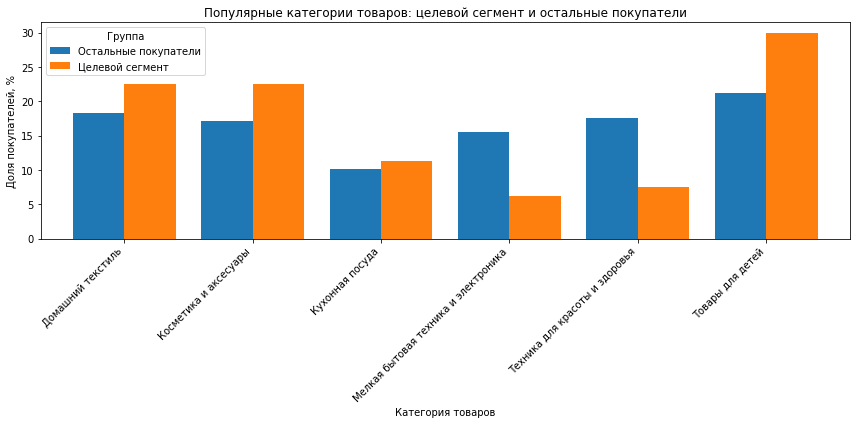

Различия в популярности категорий:


Группа,Остальные покупатели,Целевой сегмент,"Разница, п.п."
Популярная_категория,,,
Товары для детей,21.22,30.00,8.78
Косметика и аксесуары,17.14,22.50,5.36
Домашний текстиль,18.37,22.50,4.13
Кухонная посуда,10.20,11.25,1.05
Мелкая бытовая техника и электроника,15.51,6.25,-9.26
Техника для красоты и здоровья,17.55,7.50,-10.05


In [62]:

# Сравнение популярных категорий товаров
# в целевом сегменте и среди остальных покупателей

category_comparison = pd.crosstab(
    segment_comparison['Популярная_категория'],
    segment_comparison['Группа'],
    normalize='columns'
) * 100

print('Распределение популярных категорий товаров, %:')
display(category_comparison.round(2))

# Визуализация распределения категорий
category_comparison.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title(
    'Популярные категории товаров: целевой сегмент и остальные покупатели'
)
plt.xlabel('Категория товаров')
plt.ylabel('Доля покупателей, %')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Группа')
plt.tight_layout()
plt.show()

# Рассчитываем различия между группами
category_comparison['Разница, п.п.'] = (
    category_comparison['Целевой сегмент']
    - category_comparison['Остальные покупатели']
)

print('Различия в популярности категорий:')
display(
    category_comparison.sort_values(
        by='Разница, п.п.',
        ascending=False
    ).round(2)
)

### Выводы по результатам сегментации покупателей

Для углублённого исследования выбран сегмент покупателей с высокой прибылью и высоким прогнозируемым риском снижения покупательской активности.

В анализируемой тестовой выборке представлено 325 покупателей: 80 относятся к целевому сегменту, 245 — к остальным сегментам.

**1. Сравнение покупательской активности**

Покупатели целевого сегмента просматривают в среднем меньше страниц за визит по медианному показателю: 5 против 9 у остальных покупателей. Медианное количество просматриваемых категорий также ниже — 2,5 против 3.

Доля акционных покупок в целевом сегменте выше: 30% против 23%. Кроме того, медианное количество неоплаченных товаров за квартал составляет 4 против 3.

Медианная маркетинговая активность за последние шесть месяцев немного ниже (4,0 против 4,3), а в текущем месяце показатели совпадают (4,0). Медианное количество ошибок сервиса также одинаково — 4.

Наиболее заметные различия связаны с глубиной просмотра сайта, долей акционных покупок и количеством неоплаченных товаров. Эти показатели заслуживают дополнительного внимания при разработке мер по удержанию покупателей.

**2. Анализ выручки по периодам**

В целевом сегменте медианная выручка выросла с 4676,0 в препредыдущем месяце до 5005,5 в предыдущем и 5471,1 в текущем месяце. Общий прирост составил около 17,0%.

Среди остальных покупателей медианная выручка увеличилась с 4831,0 до 4965,5 и 5179,5 соответственно. Общий прирост составил около 7,2%.

Таким образом, несмотря на высокий прогнозируемый риск снижения активности, целевой сегмент демонстрирует положительную динамику медианной выручки. Это подтверждает целесообразность профилактических мероприятий по удержанию прибыльных покупателей, не дожидаясь возможного снижения их активности.

**3. Сравнение популярных товарных категорий**

В целевом сегменте наиболее популярны следующие категории:

* «Товары для детей» — 30,0% против 21,22% у остальных покупателей.
* «Косметика и аксесуары» — 22,5% против 17,14%.
* «Домашний текстиль» — 22,5% против 18,37%.

При этом категории «Мелкая бытовая техника и электроника» (6,25% против 15,51%) и «Техника для красоты и здоровья» (7,5% против 17,55%) представлены заметно реже.

Различия в предпочтениях покупателей можно использовать при формировании персонализированных предложений.

**4. Рекомендации для бизнеса**

1. **Повысить вовлечённость покупателей.** Проверить удобство навигации и поиска товаров, а также протестировать персональные рекомендации. Особое внимание уделить покупателям с небольшой глубиной просмотра сайта.
2. **Сократить количество неоплаченных товаров.** Проанализировать причины незавершённых покупок, проверить процесс оформления и оплаты заказов. Протестировать напоминания о незавершённом заказе.
3. **Разработать персонализированные акции.** Учитывая более высокую долю акционных покупок, протестировать адресные предложения для покупателей целевого сегмента. Размер скидок необходимо контролировать с учётом прибыльности.
4. **Учитывать товарные предпочтения.** Использовать категории «Товары для детей», «Косметика и аксесуары» и «Домашний текстиль» при подборе персональных рекомендаций.
5. **Контролировать результаты мероприятий.** Отслеживать изменение покупательской активности, глубины просмотра, количества неоплаченных товаров, выручки и прибыли. Эффективность новых мероприятий проверять с помощью A/B-тестирования.

**Итог:** целевой сегмент характеризуется высокой прибыльностью и прогнозируемым риском снижения покупательской активности. По сравнению с остальными покупателями он отличается меньшей глубиной просмотра сайта, большей долей акционных покупок и большим количеством неоплаченных товаров. При этом медианная выручка сегмента продолжает расти.

Приоритетными направлениями работы являются повышение вовлечённости, снижение числа незавершённых покупок и персонализация предложений. Выявленные различия являются наблюдаемыми связями и не доказывают причинно-следственное влияние отдельных факторов.


## **Шаг 9. Общий вывод**

## Общий вывод

В рамках проекта была решена задача прогнозирования снижения покупательской активности постоянных покупателей в ближайшие три месяца. Основной целью было построение модели машинного обучения, которая позволяет оценить вероятность снижения активности клиентов, а также использовать результаты моделирования и данные о прибыльности для сегментации покупателей и разработки рекомендаций по работе с наиболее важной группой клиентов.

Для анализа были использованы несколько исходных таблиц: `market_file.csv`, `market_money.csv`, `market_time.csv` и `money.csv`. В `market_file.csv` содержалась информация о покупательской активности, характеристиках клиентов, маркетинговой активности, поведении на сайте и покупках. Таблицы `market_money.csv` и `market_time.csv` содержали данные о выручке и времени, проведённом клиентами на сайте. Таблица `money.csv` использовалась для анализа прибыльности покупателей.

На этапе предобработки были проверены типы данных, пропуски и дубликаты. Таблицы с выручкой и временем были преобразованы из длинного формата в широкий, после чего объединены с основной таблицей по идентификатору покупателя. Для дальнейшего анализа были отобраны покупатели, которые совершали покупки не менее чем в трёх периодах. В ходе подготовки признаков количественные и категориальные признаки обрабатывались отдельно с помощью `ColumnTransformer`. Для кодирования категориальных признаков использовались `OneHotEncoder` и `OrdinalEncoder`, а для масштабирования количественных признаков — `StandardScaler` и `MinMaxScaler`.

Перед обучением моделей был проведён корреляционный анализ количественных признаков. Сильных корреляционных связей с коэффициентом по модулю 0,7 и выше выявлено не было, поэтому удаление признаков по причине выраженной мультиколлинеарности не потребовалось.

Для поиска лучшей модели были построены пайплайны, объединяющие предобработку данных и алгоритм машинного обучения. Были обучены и сравнены четыре модели: `KNeighborsClassifier`, `DecisionTreeClassifier`, `LogisticRegression` и `SVC`. Для каждой модели был выполнен подбор гиперпараметров с использованием `GridSearchCV`. В качестве основной метрики была выбрана `ROC-AUC`, поскольку она позволяет оценить способность модели различать покупателей с разным уровнем риска независимо от выбранного порога классификации.

По сохранённым результатам сравнения лучшей моделью стала **KNeighborsClassifier** с `n_neighbors=30`. ROC-AUC по кросс-валидации составила **0,9173**, на тестовой выборке — **0,9174**. Данная модель была выбрана для дальнейшего анализа покупателей.

Для оценки влияния признаков на прогноз модели был проведён SHAP-анализ. Наибольшее влияние на результат прогнозирования оказали признаки **`Страниц_за_визит`**, **`предыдцщий_месяц`**, **`Акционные_покупки`**, **`текущий_месяц_y`**, **`Средний_просмотр_категорий_за_визит`** и **`Неоплаченные_продукты_штук_квартал`**. Это показывает, что при прогнозировании снижения активности существенную роль играют поведение покупателей на сайте, история активности и особенности покупательского поведения.

После моделирования была выполнена сегментация покупателей с учётом двух показателей: вероятности снижения покупательской активности и прибыльности. Были выделены четыре сегмента: «Высокая прибыль / высокий риск», «Высокая прибыль / низкий риск», «Низкая прибыль / высокий риск» и «Низкая прибыль / низкий риск».

Для дополнительного исследования был выбран сегмент **«Высокая прибыль / высокий риск»**. В него вошло **80 покупателей (24,62% от тестовой выборки)**. Средняя прибыль покупателей данного сегмента составляет **4,677**, а средняя вероятность снижения активности — **0,729**. Данный сегмент является наиболее важным с точки зрения удержания клиентов, поскольку покупатели обладают высокой ценностью для компании, но одновременно имеют высокий риск снижения активности.

Для работы с этим сегментом рекомендуется использовать персонализированные предложения: специальные скидки и промокоды на интересующие категории товаров, персональные акции, рекомендации товаров на основе предыдущего поведения, а также дополнительные коммуникации с клиентами. При этом предложения следует делать адресными, чтобы не снижать прибыльность клиентов чрезмерными скидками. Особое внимание рекомендуется уделять показателям посещаемости сайта, количеству просмотренных категорий, акционным покупкам и другим признакам, которые показали высокую значимость в SHAP-анализе.

Таким образом, построенная модель позволяет не только прогнозировать риск снижения покупательской активности, но и использовать полученные результаты для принятия бизнес-решений. Наиболее перспективным направлением является раннее выявление прибыльных клиентов с высоким риском снижения активности и проведение для них персонализированных мероприятий по удержанию и повышению покупательской активности.
